# [GSE66390](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE66390)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2020-11-18
> - Modified: 2025-02-23

# 1. Experimental Design

> The landscape of accessible chromatin in mammalian pre-implantation embryos.
> - Wu, J., Huang, B., Chen, H. et al. The landscape of accessible chromatin in mammalian preimplantation embryos. Nature 534, 652–657 (2016). https://doi.org/10.1038/nature18606.
> - Smart-Seq2
> - Illumina HiSeq 1500, PE50
> - mm10

| Sample | Organism | Source | Strain | Stage | Replicate |
| - | - | - | - | - | - |
| MIIoocyte | Mus musculus | Oocyte | C57BL/6N | MII oocyte | rep1~2 |
| Zygote | Mus musculus | Embryo | C57BL/6N | Zygote | rep1~2 |
| early2cell | Mus musculus | Embryo | C57BL/6N | early2cell | rep1~2 |
| 2cell | Mus musculus | Embryo | C57BL/6N | 2cell | rep1~2 |
| 4cell | Mus musculus | Embryo | C57BL/6N | 4cell | rep1~2 |
| 8cell | Mus musculus | Embryo | C57BL/6N | 8cell | rep1~2 |
| ICM | Mus musculus | Blastocyst, Inner Cell Mass | C57BL/6N | ICM | rep1~2 |
| mESC | Mus musculus | Embryonic Stem Cell | C57BL/6N | ESC | rep1~2 |

> Note:
> - Mouse preimplantation embryos were obtained from crosses of C57BL/6N and DBA/2N.

# 2. Preprocessing

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(limma))
suppressPackageStartupMessages(library(edgeR))
suppressPackageStartupMessages(library(DESeq2))
suppressPackageStartupMessages(library(ggrepel))
suppressPackageStartupMessages(library(pheatmap))
suppressPackageStartupMessages(library(patchwork))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


## 1). Import Data

In [2]:
data_dir <- "~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Embryos_GSE66390/02_output"

In [3]:
stage_levels <- c("MIIoocyte", "Zygote", "early2cell", "2cell", "4cell", "8cell", "ICM", "mESC")

### a). FeatureCounts

In [4]:
raw_counts <- file.path(data_dir, "04_counts", "featureCounts.tsv") |>
  read.table(header = TRUE, sep = "\t", check.names = FALSE)

colnames(raw_counts) <- colnames(raw_counts) |> 
  sub("^02_output/03_align/(.*?).Aligned.out.bam", "\\1", x = _) |>
  gsub(pattern = "-", replacement = "_")

dim(raw_counts)

[1] 55335    24

In [5]:
coldata <- colnames(raw_counts) |>
    tibble(sample = _) |>
    filter(str_detect(sample, fixed("rep"))) |>
    separate(
        col = sample, into = c("Stage", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        Stage = factor(Stage, levels = stage_levels), 
        Replicate = factor(Replicate)) |> 
    arrange(Stage, Replicate) |>
    column_to_rownames("sample")

coldata

,Stage,Replicate
,<fct>,<fct>
MIIoocyte_rep1,MIIoocyte,rep1
MIIoocyte_rep2,MIIoocyte,rep2
Zygote_rep1,Zygote,rep1
Zygote_rep2,Zygote,rep2
early2cell_rep1,early2cell,rep1
early2cell_rep2,early2cell,rep2
2cell_rep1,2cell,rep1
2cell_rep2,2cell,rep2
4cell_rep1,4cell,rep1


In [6]:
anno_gene <- raw_counts |> 
    select(
        Geneid, symbol = gene_name, type = gene_type, 
        basepairs = Length) |>
    column_to_rownames(var = "Geneid") |> 
    DataFrame()

In [7]:
raw_counts <- raw_counts |>
    column_to_rownames("Geneid") |>
    select(matches("rep")) |>
    select(any_of(rownames(coldata))) |>
    as.matrix()

In [8]:
DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Stage)

class: DESeqDataSet 
dim: 55335 16 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(16): MIIoocyte_rep1 MIIoocyte_rep2 ... mESC_rep1 mESC_rep2
colData names(2): Stage Replicate

### b). HTseq-count

In [9]:
htseq_files <- file.path(data_dir, "04_counts") |>
    list.files(pattern = ".tsv") |>
    str_subset(pattern = "featureCounts", negate = TRUE)

In [10]:
coldata <- tibble(
    sampleName = sub("(.*?).tsv", "\\1", htseq_files),
    fileName = htseq_files) |> 
    separate(
        col = sampleName, into = c("Stage", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        Stage = factor(Stage, levels = stage_levels), 
        Replicate = factor(Replicate)) |> 
    arrange(Stage, Replicate) |>
    select("sampleName", "fileName", "Stage", "Replicate") |>
    as.data.frame()

In [11]:
DESeqDataSetFromHTSeqCount(
    sampleTable = coldata, design = ~ Stage,
    directory = file.path(data_dir, "04_counts"))

class: DESeqDataSet 
dim: 55335 16 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(16): MIIoocyte_rep1 MIIoocyte_rep2 ... mESC_rep1 mESC_rep2
colData names(2): Stage Replicate

### c). Salmon

#### tximport

In [12]:
gtf <- rtracklayer::import(
    "~/reference/Mus_musculus/mm10/gencode.vM23.annotation.gtf")

tx2gene <- gtf |> 
    subset(
        type == "transcript", 
        select = c("transcript_id", "gene_id")) |> 
    mcols()

In [13]:
salmon_dir <- file.path(data_dir, "05_salmon")
salmon_files <- list.dirs(salmon_dir, recursive = FALSE, full.names = FALSE)
salmon_quants <- setNames(
    file.path(salmon_dir, salmon_files, "quant.sf"),
    salmon_files)

In [14]:
coldata <- tibble(sample = names(salmon_quants)) |> 
    separate(
        col = sample, into = c("Stage", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        Stage = factor(Stage, levels = stage_levels), 
        Replicate = factor(Replicate)) |> 
    arrange(Stage, Replicate) |>
    column_to_rownames("sample")

salmon_quants <- salmon_quants[rownames(coldata)]

In [15]:
# suppressPackageStartupMessages(library(tximport))
txi <- tximport::tximport(
    salmon_quants, type = "salmon", tx2gene = tx2gene, 
    ignoreAfterBar = TRUE, ignoreTxVersion = FALSE)

reading in files with read_tsv

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 
13 
14 
15 
16 


summarizing abundance

summarizing counts

summarizing length



In [16]:
DESeqDataSetFromTximport(txi, colData = coldata, design = ~ Stage)

using counts and average transcript lengths from tximport



class: DESeqDataSet 
dim: 54281 16 
metadata(1): version
assays(2): counts avgTxLength
rownames(54281): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(16): MIIoocyte_rep1 MIIoocyte_rep2 ... mESC_rep1 mESC_rep2
colData names(2): Stage Replicate

#### tximeta

In [17]:
salmon_dirs <- file.path(data_dir, "05_salmon") |>
    list.dirs(recursive = FALSE, full.names = FALSE)

In [18]:
coldata <- tibble(
    names = salmon_dirs, 
    files = file.path(data_dir, "05_salmon", salmon_dirs, "quant.sf")) |> 
    separate(
        col = names, into = c("Stage", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        Stage = factor(Stage, levels = stage_levels), 
        Replicate = factor(Replicate)) |> 
    arrange(Stage, Replicate) |>
    select("names", "files", "Stage", "Replicate") |>
    as.data.frame()

In [19]:
# suppressPackageStartupMessages(library(tximeta))
tximeta::makeLinkedTxome(
    indexDir = "~/reference/Mus_musculus/mm10/index/salmon_index", 
    source = "GENCODE", organism = "Mus musculus", 
    release = "M23", genome = "GRCm38",
    fasta = "~/reference/Mus_musculus/mm10/gencode.vM23.transcripts.fa", 
    gtf = "~/reference/Mus_musculus/mm10/index/genome.gtf", 
    write = FALSE)

reading digest from indexDir: ~/reference/Mus_musculus/mm10/index/salmon_index

NOTE: linkedTxome with source='GENCODE', set useHub=FALSE in tximeta
to avoid download of reference txome from AnnotationHub.
alternatively use a different string for source argument, e.g. LocalGENCODE

saving linkedTxome in bfc (first time)



In [20]:
# There is a network problem
se <- tximeta::tximeta(coldata, useHub = FALSE)
gse <- tximeta::summarizeToGene(se)

importing salmon quantification files

reading in files with read_tsv

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 
13 
14 
15 
16 


found matching linkedTxome:
[ GENCODE - Mus musculus - release M23 ]

building TxDb with 'txdbmaker' package

Import genomic features from the file as a GRanges object ... 
OK

Prepare the 'metadata' data frame ... 
OK

Make the TxDb object ... 
Warning message in .get_cds_IDX(mcols0$type, mcols0$phase):
"The "phase" metadata column contains non-NA values for features of type
  stop_codon. This information was ignored."
Warning message in .makeTxDb_normarg_chrominfo(chrominfo):
"genome version information is not available for this TxDb object"
OK

generating transcript ranges

fetching genome info for GENCODE

loading existing TxDb created: 2026-06-21 16:53:35

Loading required package: GenomicFeatures

Loading required package: AnnotationDbi


Attaching package: 'AnnotationDbi'


The following object is masked from 'package:dplyr':

    select


obtaining tra

In [21]:
DESeqDataSet(gse, design = ~ Stage)

using counts and average transcript lengths from tximeta



class: DESeqDataSet 
dim: 54281 16 
metadata(8): tximetaInfo quantInfo ... assignRanges version
assays(3): counts abundance avgTxLength
rownames(54281): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(2): gene_id tx_ids
colnames(16): MIIoocyte_rep1 MIIoocyte_rep2 ... mESC_rep1 mESC_rep2
colData names(3): names Stage Replicate

### d). kallisto

#### tximport

In [22]:
kallisto_dir <- file.path(data_dir, "05_kallisto")
kallisto_files <- list.dirs(kallisto_dir, recursive = FALSE, full.names = FALSE)
kallisto_quants <- setNames(
    file.path(kallisto_dir, kallisto_files, "abundance.h5"),
    kallisto_files)

In [23]:
coldata <- tibble(sample = names(kallisto_quants)) |> 
    separate(
        col = sample, into = c("Stage", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        Stage = factor(Stage, levels = stage_levels), 
        Replicate = factor(Replicate)) |> 
    arrange(Stage, Replicate) |>
    column_to_rownames("sample")

kallisto_quants <- kallisto_quants[rownames(coldata)]

In [24]:
# suppressPackageStartupMessages(library(tximport))
txi <- tximport::tximport(
    kallisto_quants, type = "kallisto", tx2gene = tx2gene, 
    ignoreAfterBar = TRUE, ignoreTxVersion = FALSE)

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 
13 
14 
15 
16 


summarizing abundance

summarizing counts

summarizing length



In [25]:
DESeqDataSetFromTximport(txi, colData = coldata, design = ~ Stage)

using counts and average transcript lengths from tximport



class: DESeqDataSet 
dim: 55335 16 
metadata(1): version
assays(2): counts avgTxLength
rownames(55335): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(16): MIIoocyte_rep1 MIIoocyte_rep2 ... mESC_rep1 mESC_rep2
colData names(2): Stage Replicate

## 2). Object Construction

In [26]:
eSet <- SummarizedExperiment(
    assays = list(counts = raw_counts), 
    rowData = anno_gene, colData = coldata)

eSet

class: SummarizedExperiment 
dim: 55335 16 
metadata(0):
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(16): MIIoocyte_rep1 MIIoocyte_rep2 ... mESC_rep1 mESC_rep2
colData names(2): Stage Replicate

In [27]:
dds <- DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Stage)

dds

class: DESeqDataSet 
dim: 55335 16 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(16): MIIoocyte_rep1 MIIoocyte_rep2 ... mESC_rep1 mESC_rep2
colData names(2): Stage Replicate

In [28]:
dgel <- DGEList(
    counts = raw_counts, genes = anno_gene, 
    samples = coldata, group = coldata$Stage)

## 3). Low-Count Filtering

> - Filter low expressed genes to reduce the size of the object and increase the speed of the function

In [29]:
keep <- rowSums(assay(eSet) >= 10) >= 2
# keep <- rowSums(counts(dds) >= 10) >= 2

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

eSet <- eSet[keep, ]
dds <- dds[keep, ]

Filtered genes summary:
 Pass: 18955 
 Remove: 36380 
 Retention rate: 34.25 %


In [30]:
keep <- filterByExpr(dgel, group = dgel$samples$group)

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

dgel <- dgel[keep, , keep.lib.sizes = FALSE]
# Normalize Library Sizes
dgel <- normLibSizes(dgel)

Filtered genes summary:
 Pass: 18019 
 Remove: 37316 
 Retention rate: 32.56 %


# 3. Normalization

In [31]:
tpm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs, FUN = "/") |>
    (\(rpk) sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6)()

In [32]:
dds <- estimateSizeFactors(dds)
norm_fpkm <- fpkm(dds, robust = TRUE)

In [33]:
norm_cpm <- cpm(dgel, normalized.lib.sizes = TRUE, log = FALSE)

In [34]:
design <- model.matrix(~ group, data = dgel$samples)
norm_v <- voom(dgel, design, plot = FALSE)

In [35]:
rld <- rlog(dds, blind = FALSE)

In [36]:
suppressPackageStartupMessages(library(vsn))

In [37]:
common_theme <- theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [38]:
p1 <- meanSdPlot(log2(counts(dds) + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](Count+1))) + 
    common_theme
p2 <- meanSdPlot(log2(tpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](TPM+1))) + 
    common_theme
p3 <- meanSdPlot(assay(rld), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "rlog") + 
    common_theme
p4 <- meanSdPlot(log2(norm_fpkm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "DESeq2, FPKM") + 
    common_theme
p5 <- meanSdPlot(log2(norm_cpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "edgeR's TMM, CPM") + 
    common_theme
p6 <- meanSdPlot(norm_v$E, ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "limma's voom") + 
    common_theme

Warning message:
"`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the vsn package.
  Please report the issue to the authors."


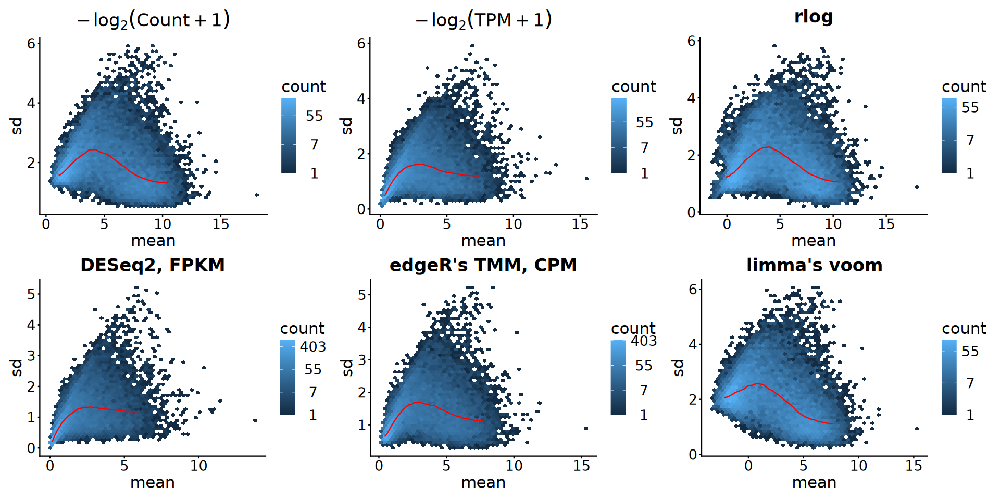

In [39]:
options(repr.plot.width = 16, repr.plot.height = 8)
(p1 + p2 + p3) / (p4 + p5 + p6)

# 4. Exploration

In [40]:
norm_mat <- log2(tpm + 1)
norm_vs <- assay(rld)

### 1). Overview

In [41]:
plot_df <- colData(eSet) |> as.data.frame() |>
    arrange(Stage, Replicate) |> 
    rownames_to_column(var = "Sample") |>
    mutate(librarySize = colSums(assay(eSet))[Sample])

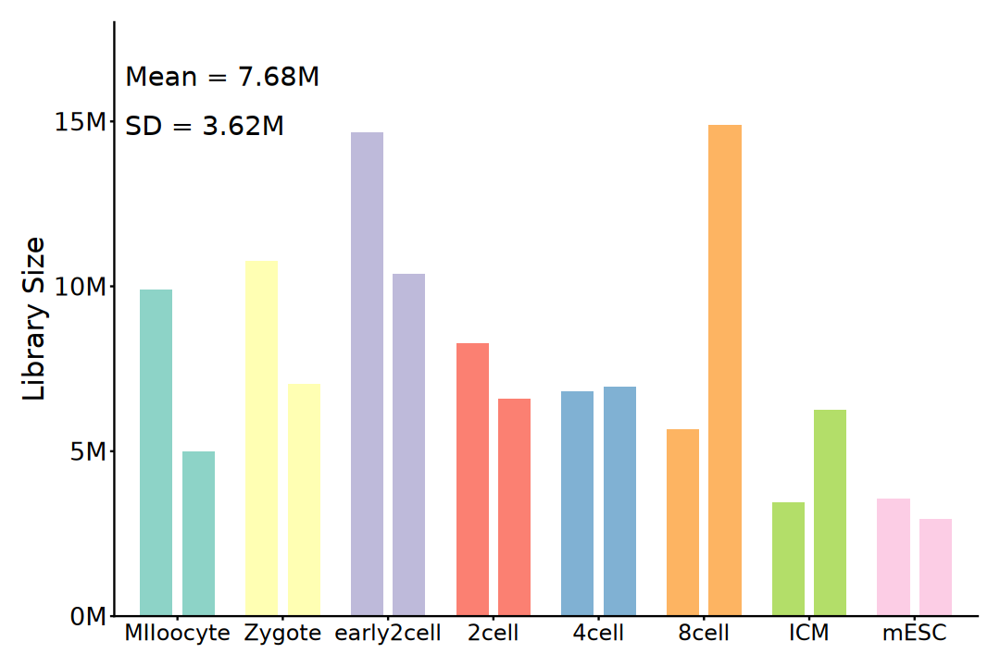

In [42]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Stage, y = librarySize)) +
    geom_col(
        aes(fill = Stage, group = Sample), stat = "identity",
        position = position_dodge(width = 0.8),
        width = 0.6, show.legend = FALSE) +
    annotate(
        geom = "text", x = 0.5, y = max(plot_df$librarySize) * 1.1,
        label = paste0("Mean = ", round(mean(plot_df$librarySize) / 1e6, 2), "M"),
        hjust = 0, size = 6) +
    annotate(
        geom = "text", x = 0.5, y = max(plot_df$librarySize) * 1.0,
        label = paste0("SD = ", round(sd(plot_df$librarySize) * 1e-6, 2), "M"),
        hjust = 0, size = 6) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"),
        expand = expansion(mult = c(0, 0.1))) +
    scale_fill_brewer(palette = "Set3") +
    labs(x = NULL, y = "Library Size") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        axis.title = element_text(size = 18),
        axis.text.x = element_text(size = 14),
        axis.text.y = element_text(size = 16))

## 2). PCA

In [43]:
top_var_idx <- norm_mat |>
    rowSds() |>
    # (\(m) rowSds(m) / rowMeans2(m))() |> # CV
    tibble::enframe(name = "row", value = "sd") |>
    slice_max(order_by = sd, n = 2000) |>
    pull(row)
# CV can eliminate the bias that "high abundance tends to have large variance".

In [44]:
pca_res <- norm_mat[top_var_idx, ] |> t() |> 
    prcomp(center = TRUE, scale. = FALSE)

per_var <- round(100 * pca_res$sdev^2 / sum(pca_res$sdev^2), 2)

pca_df <- merge(pca_res$x, colData(eSet), by = "row.names")

In [45]:
p1 <- ggplot(pca_df, aes(PC1, PC2)) +
    geom_point(aes(color = Stage, shape = Replicate), size = 5) +
    geom_smooth(
        formula = "y ~ x", method = "loess", se = FALSE,
        color = "grey", linewidth = 1) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = bquote("PCA for" ~ -log[2](TPM+1)), 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [46]:
pca_res <- plotPCA(
    rld, intgroup = c("Stage", "Replicate"), 
    ntop = 2000, returnData = TRUE)

per_var <- round(100 * attr(pca_res, "percentVar"))

using ntop=2000 top features by variance



In [47]:
p2 <- ggplot(pca_res, aes(PC1, PC2)) +
    geom_point(aes(color = Stage, shape = Replicate), size = 5) +
    geom_smooth(
        formula = "y ~ x", method = "loess", se = FALSE,
        color = "grey", linewidth = 1) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = "PCA for rlog", 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [48]:
# Generalized principal component analysis (GLM-PCA)
# suppressPackageStartupMessages(library(glmpca))
set.seed(123)

gpca <- glmpca::glmpca(assay(eSet)[top_var_idx, ], L = 2)

gpca_df <- merge(gpca$factors, colData(eSet), by = "row.names")

In [49]:
p3 <- ggplot(gpca_df, aes(dim1, dim2)) +
    geom_point(aes(color = Stage, shape = Replicate), size = 5) +
    geom_smooth(
        formula = "y ~ x", method = "loess", se = FALSE,
        color = "grey", linewidth = 1) +
    scale_color_brewer(palette = "Set1") +
    labs(title = "GLM-PCA for raw count", x = "PC1", y = "PC2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)),
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

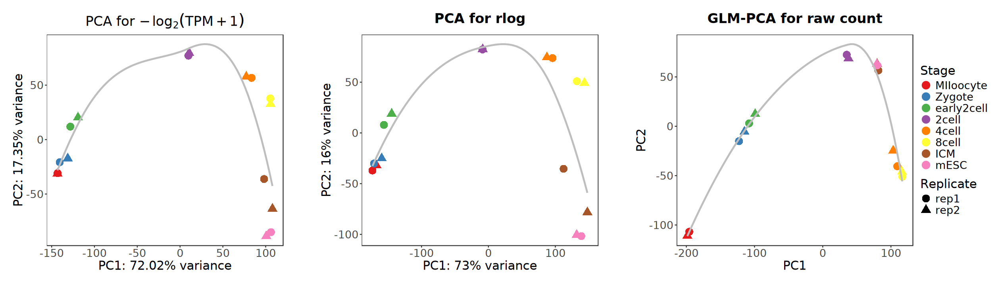

In [50]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(nrow = 1, guides = "collect", 
                widths = c(1, 0.05, 1, 0.05, 1))

## 3). MDS

> Multidimensional scaling

In [51]:
dist_mat <- norm_mat[top_var_idx, ] |> t() |> dist()

mds <- colData(eSet) |> as.data.frame() |>
    cbind(cmdscale(as.matrix(dist_mat)))

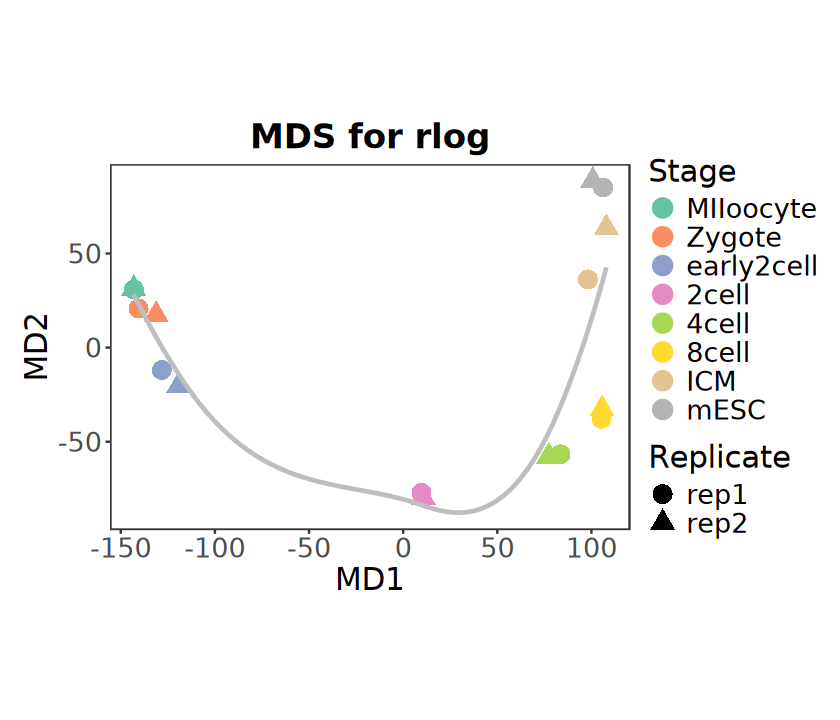

In [52]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(mds, aes(x = `1`, y = `2`)) +
    geom_point(aes(color = Stage, shape = Replicate), size = 5) +
    geom_smooth(
        formula = "y ~ x", method = "loess", se = FALSE,
        color = "grey", linewidth = 1) +
    # geom_path(
    #     aes(group = 1), color = "black", 
    #     arrow = arrow(length = unit(0.15, "inches"))) +
    scale_color_brewer(palette = "Set2") +
    coord_fixed() + 
    labs(title = "MDS for rlog", x = "MD1", y = "MD2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 4). PCoA

> Principal coordinate analysis

In [53]:
# 1. Calculate Bray-Curtis distance on the transposed count matrix
dist_mat <- norm_vs[top_var_idx, ] |> t() |> 
    vegan::vegdist(method = "bray")

# 2. Run PCoA
pcoa_res <- cmdscale(dist_mat, k = 2, eig = TRUE)

# 3. Prepare data for plot
pcoa_df <- merge(pcoa_res$points, colData(eSet), by = "row.names")

Warning message in vegan::vegdist(t(norm_vs[top_var_idx, ]), method = "bray"):
"results may be meaningless because data have negative entries
                 in method "bray""


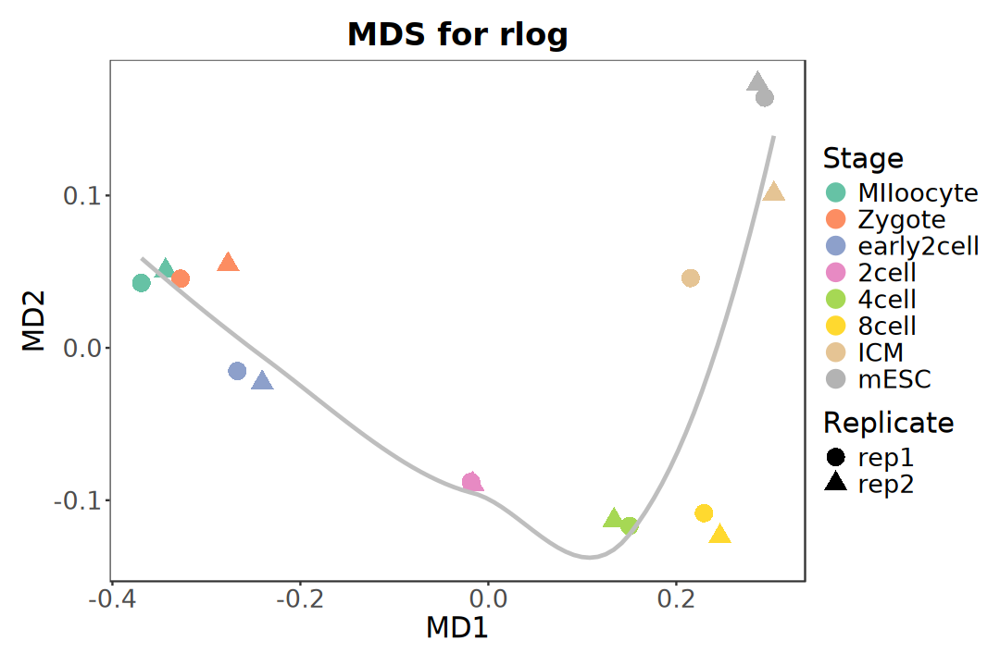

In [54]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(pcoa_df, aes(x = V1, y = V2)) +
    geom_point(aes(color = Stage, shape = Replicate), size = 5) +
    geom_smooth(
        formula = "y ~ x", method = "loess", se = FALSE,
        color = "grey", linewidth = 1) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "MDS for rlog", x = "MD1", y = "MD2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 5). Sample Correlation

In [55]:
ac <- colData(eSet) |> as.data.frame() |>
    dplyr::select(Replicate, Stage)

In [56]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(eSet$Stage)),
    levels(eSet$Stage))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(eSet$Replicate)),
    levels(eSet$Replicate))

anno_colors <- list(
    Stage = group_colors,
    Replicate = replicate_colors)

colors <- colorRampPalette(brewer.pal(9, "Blues"))(255)

In [57]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

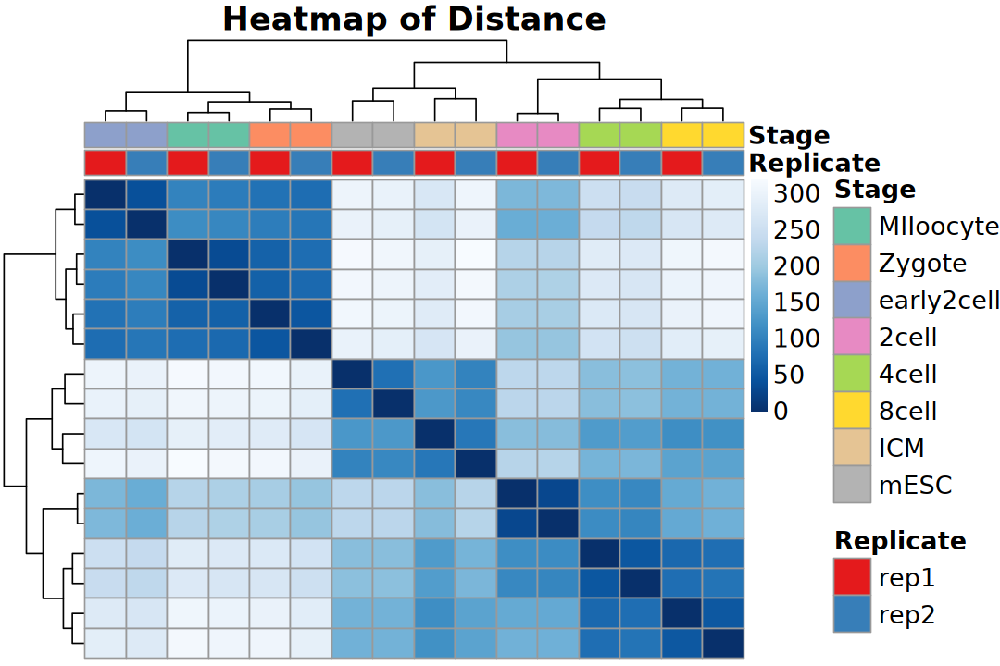

In [58]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = dist_mat,
    clustering_distance_cols = dist_mat,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 6). Sample Correlation

In [59]:
cor_mat <- cor(norm_vs[top_var_idx, ], method = "spearman")

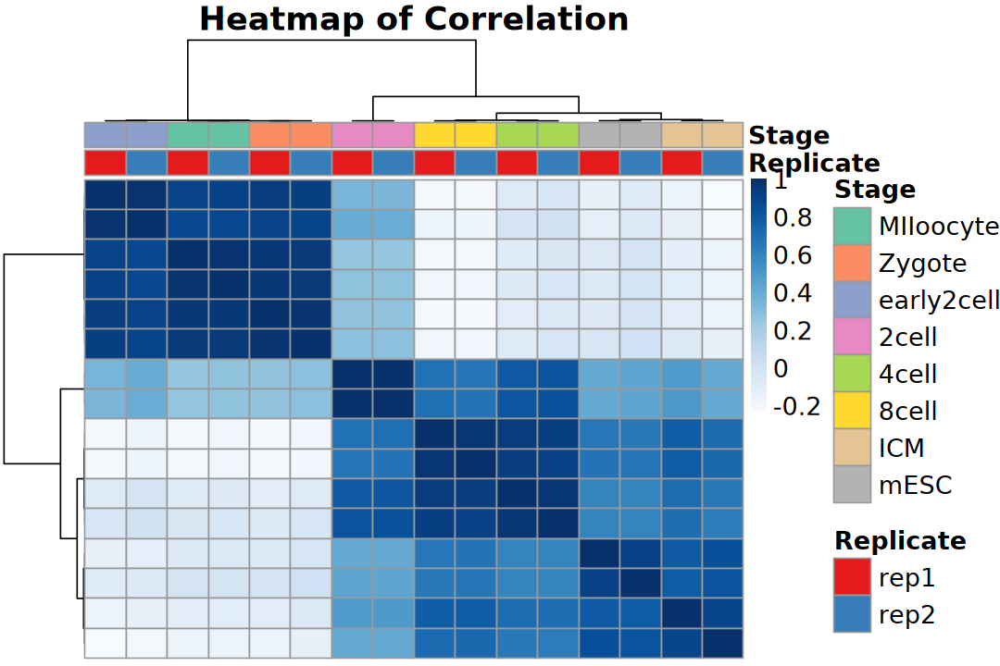

In [60]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation",
    clustering_distance_cols = "correlation",
    annotation_col = ac, col = colors, 
    annotation_colors = anno_colors,
    main = "Heatmap of Correlation", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 7). Heatmap

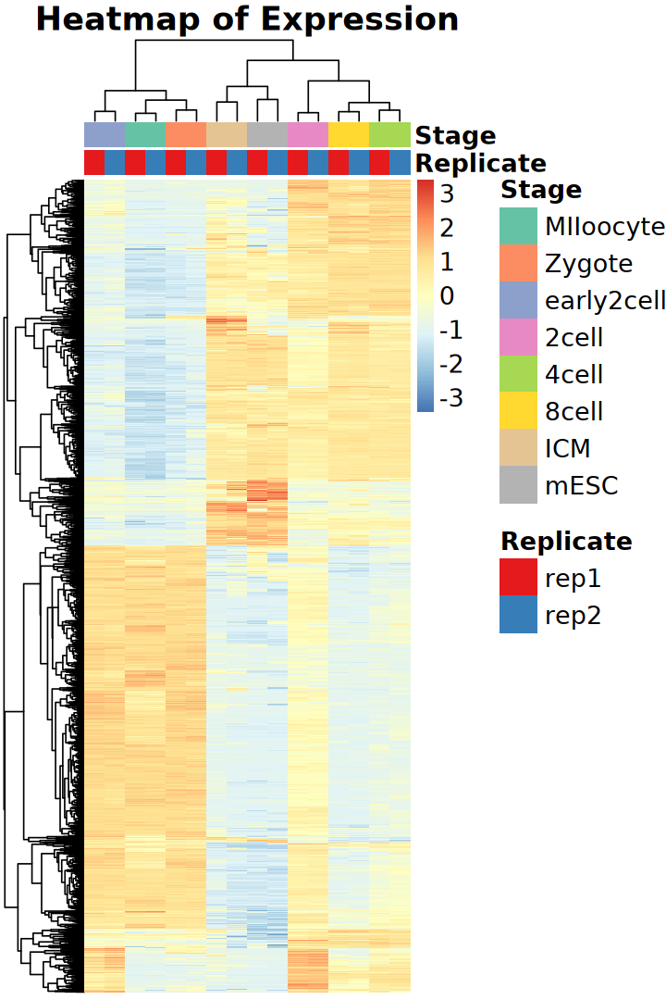

In [61]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    norm_mat[top_var_idx, ], scale = "row", 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

# 5. DEGs: Pairwise

> Sequential pairwise contrast is a differential expression analysis strategy that compares consecutive time points or developmental stages to identify stage-specific transcriptional dynamics. The primary advantage of this localized approach lies in its ability to capture temporal gene expression trajectories and pinpoint critical transition windows with high chronological resolution. However, this sequential strategy inevitably escalates the multiple-testing burden and may overlook cumulative expression changes spanning distant stages. Consequently, it is frequently complemented by global or longitudinal analytical frameworks to achieve a holistic view of the transcriptomic landscape.

In [62]:
logfc_cutoff <- log2(4)
p_cutoff <- 0.05

## a). DESeq2

> median of ratios for normalization

In [63]:
design(dds) <- ~ 0 + Stage
design(dds)

~0 + Stage

In [64]:
dds <- DESeq(dds)

using pre-existing size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [65]:
resultsNames(dds)

[1] "StageMIIoocyte"  "StageZygote"     "Stageearly2cell" "Stage2cell"     
[5] "Stage4cell"      "Stage8cell"      "StageICM"        "StagemESC"

In [66]:
group_levels <- levels(dds$Stage)

contrast_pairs <- map2(
    group_levels[-1], group_levels[-length(group_levels)],
    ~ c(.x, .y))

contrast_labels <- contrast_pairs |>
    map_chr(~ paste0(.x[1], "_vs_", .x[2]))
contrast_labels

[1] "Zygote_vs_MIIoocyte"  "early2cell_vs_Zygote" "2cell_vs_early2cell" 
[4] "4cell_vs_2cell"       "8cell_vs_4cell"       "ICM_vs_8cell"        
[7] "mESC_vs_ICM"

In [67]:
deseq2_result_list <- map(contrast_pairs, function(lv) {
    results(dds, contrast = c("Stage", lv[1], lv[2])) |>
        as.data.frame() |> 
        rownames_to_column("gene_id") |>
        dplyr::rename(logFC = log2FoldChange) |>
        mutate(
            method = "DESeq2",
            contrast = paste0(lv[1], "_vs_", lv[2]),
            result = case_when(
                padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
                padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
                TRUE ~ "NS"
            ) |> factor(levels = c("Up", "Down", "NS"))) |>
        left_join(
            rowData(dds) |> as.data.frame() |> 
                dplyr::select(symbol, type, basepairs) |>
                rownames_to_column("gene_id"), 
            by = "gene_id")
}) |> set_names(contrast_labels)

In [68]:
deseq2_result_df <- bind_rows(deseq2_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(deseq2_result_df$contrast, deseq2_result_df$result)

                      
                          Up  Down    NS
  Zygote_vs_MIIoocyte    693   233 18029
  early2cell_vs_Zygote   524    92 18339
  2cell_vs_early2cell   2978  3589 12388
  4cell_vs_2cell         501  2002 16452
  8cell_vs_4cell         205   539 18211
  ICM_vs_8cell          1732  1626 15597
  mESC_vs_ICM            897  1859 16199

## b). edgeR

> Trimmed Mean of M-values (TMM)
> 
> Quasi-likelihood pipeline

In [69]:
table(deseq2_result_df$contrast)


 Zygote_vs_MIIoocyte early2cell_vs_Zygote  2cell_vs_early2cell 
               18955                18955                18955 
      4cell_vs_2cell       8cell_vs_4cell         ICM_vs_8cell 
               18955                18955                18955 
         mESC_vs_ICM 
               18955 

In [70]:
name_map <- c(
    "MIIoocyte"   = "MII_Oocyte",
    "Zygote"      = "Zygote",
    "early2cell"  = "Early_2C",
    "2cell"       = "Stage_2C",
    "4cell"       = "Stage_4C",
    "8cell"       = "Stage_8C",
    "ICM"         = "ICM",
    "mESC"        = "mESC"
)

In [71]:
design <- model.matrix(~ 0 + group, data = dgel$samples)
colnames(design) <- name_map[levels(dgel$samples$group)]
head(design)

,MII_Oocyte,Zygote,Early_2C,Stage_2C,Stage_4C,Stage_8C,ICM,mESC
MIIoocyte_rep1,1,0,0,0,0,0,0,0
MIIoocyte_rep2,1,0,0,0,0,0,0,0
Zygote_rep1,0,1,0,0,0,0,0,0
Zygote_rep2,0,1,0,0,0,0,0,0
early2cell_rep1,0,0,1,0,0,0,0,0
early2cell_rep2,0,0,1,0,0,0,0,0


In [72]:
group_levels <- name_map[levels(dgel$samples$Stage)]
group_levels <- unname(group_levels)

contrast_pairs <- map2(
    group_levels[-1], group_levels[-length(group_levels)], 
    ~ c(.x, .y))

contrast_labels <- contrast_pairs |>
    map_chr(~ paste0(.x[1], "_vs_", .x[2]))
contrast_labels

contrast_matrix <- contrast_pairs |> 
    map(function(lv) {paste0(lv[1], "-", lv[2])}) |>
    makeContrasts(contrasts = _, levels = design)
contrast_matrix

[1] "Zygote_vs_MII_Oocyte" "Early_2C_vs_Zygote"   "Stage_2C_vs_Early_2C"
[4] "Stage_4C_vs_Stage_2C" "Stage_8C_vs_Stage_4C" "ICM_vs_Stage_8C"     
[7] "mESC_vs_ICM"

,Zygote-MII_Oocyte,Early_2C-Zygote,Stage_2C-Early_2C,Stage_4C-Stage_2C,Stage_8C-Stage_4C,ICM-Stage_8C,mESC-ICM
MII_Oocyte,-1,0,0,0,0,0,0
Zygote,1,-1,0,0,0,0,0
Early_2C,0,1,-1,0,0,0,0
Stage_2C,0,0,1,-1,0,0,0
Stage_4C,0,0,0,1,-1,0,0
Stage_8C,0,0,0,0,1,-1,0
ICM,0,0,0,0,0,1,-1
mESC,0,0,0,0,0,0,1


In [73]:
dgel <- estimateDisp(dgel, design)
# quasi-likelihood (QL) F-test
fit <- glmQLFit(dgel, design)

In [74]:
edger_qlf_result_list <- map(colnames(contrast_matrix), function(idx) {
    glmQLFTest(fit, contrast = contrast_matrix[, idx]) |>
        topTags(n = Inf) |>
        as.data.frame() |>
        rownames_to_column("gene_id") |>
        dplyr::rename(padj = FDR, pvalue = PValue) |>
        mutate(
            method = "edgeR",
            contrast = gsub(idx, pattern = "-", replacement = "_vs_"),
            result = case_when(
                padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
                padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
                TRUE ~ "NS"
            ) |> factor(levels = c("Up", "Down", "NS")))
}) |> set_names(contrast_labels)

In [75]:
edger_qlf_result_df <- bind_rows(edger_qlf_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(edger_qlf_result_df$contrast, edger_qlf_result_df$result)

                      
                          Up  Down    NS
  Zygote_vs_MII_Oocyte   574   238 17207
  Early_2C_vs_Zygote     458   101 17460
  Stage_2C_vs_Early_2C  4036  3600 10383
  Stage_4C_vs_Stage_2C   486  2378 15155
  Stage_8C_vs_Stage_4C   193   363 17463
  ICM_vs_Stage_8C       1990  1973 14056
  mESC_vs_ICM            808  2166 15045

## c). limma

> In the limma approach to RNA-seq, read counts are converted to log2-counts-per-million (logCPM), and the mean-variance relationship is modeled either with precision weights or with an empirical Bayes prior trend. The precision weights approach is called “voom,” and the prior trend approach is called “limma-trend.”

In [76]:
name_map <- c(
    "MIIoocyte"   = "MII_Oocyte",
    "Zygote"      = "Zygote",
    "early2cell"  = "Early_2C",
    "2cell"       = "Stage_2C",
    "4cell"       = "Stage_4C",
    "8cell"       = "Stage_8C",
    "ICM"         = "ICM",
    "mESC"        = "mESC"
)

In [77]:
design <- model.matrix(~ 0 + group, data = dgel$samples)
colnames(design) <- name_map[levels(dgel$samples$group)]
head(design)

,MII_Oocyte,Zygote,Early_2C,Stage_2C,Stage_4C,Stage_8C,ICM,mESC
MIIoocyte_rep1,1,0,0,0,0,0,0,0
MIIoocyte_rep2,1,0,0,0,0,0,0,0
Zygote_rep1,0,1,0,0,0,0,0,0
Zygote_rep2,0,1,0,0,0,0,0,0
early2cell_rep1,0,0,1,0,0,0,0,0
early2cell_rep2,0,0,1,0,0,0,0,0


In [78]:
group_levels <- name_map[levels(dgel$samples$Stage)]
group_levels <- unname(group_levels)

contrast_pairs <- map2(
    group_levels[-1], group_levels[-length(group_levels)], 
    ~ c(.x, .y))

contrast_labels <- contrast_pairs |>
    map_chr(~ paste0(.x[1], "_vs_", .x[2]))

contrast_matrix <- contrast_pairs |> 
    map(function(lv) {paste0(lv[1], "-", lv[2])}) |>
    makeContrasts(contrasts = _, levels = design)

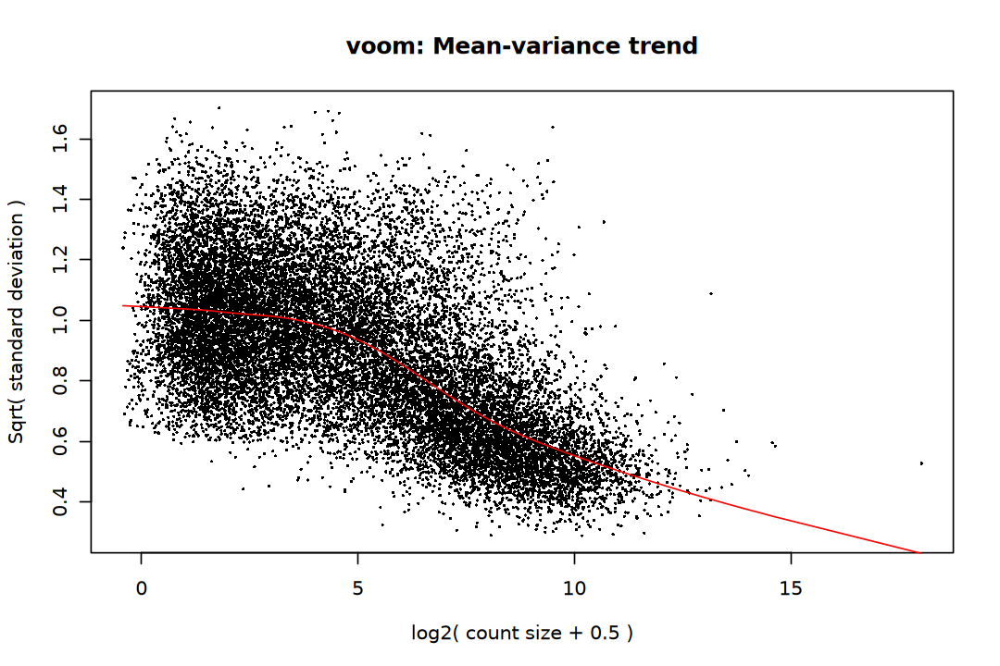

In [79]:
options(repr.plot.width = 9, repr.plot.height = 6)

norm_v <- voom(dgel, design, plot = TRUE)

In [80]:
# Linear Model for Series of Arrays
fit <- lmFit(norm_v, design)
# Compute contrasts from linear model fit
fit <- contrasts.fit(fit, contrast_matrix)
# Empirical Bayes Statistics for Differential Expression
fit <- eBayes(fit)

In [81]:
limma_result_list <- map(colnames(contrast_matrix), function(idx) {
    topTable(fit, coef = idx, number = Inf) |>
        as.data.frame() |>
        rownames_to_column("gene_id") |>
        dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
        mutate(
            method = "limma",
            contrast = gsub(idx, pattern = "-", replacement = "_vs_"),
            result = case_when(
                padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
                padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
                TRUE ~ "NS"
            ) |> factor(levels = c("Up", "Down", "NS")))
}) |> set_names(contrast_labels)

In [82]:
limma_result_df <- bind_rows(limma_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(limma_result_df$contrast, limma_result_df$result)

                      
                          Up  Down    NS
  Zygote_vs_MII_Oocyte   537   211 17271
  Early_2C_vs_Zygote     535   111 17373
  Stage_2C_vs_Early_2C  4038  3557 10424
  Stage_4C_vs_Stage_2C   484  2615 14920
  Stage_8C_vs_Stage_4C   216   353 17450
  ICM_vs_Stage_8C       1897  2241 13881
  mESC_vs_ICM            607  2629 14783

## DEGs Evaluation

In [83]:
deseq2_result_df <- deseq2_result_df |>
    separate(
        contrast, into = c("v1", "v2"), 
        sep = "_vs_", remove = FALSE) |>
    mutate(v1 = name_map[v1], v2 = name_map[v2]) |>
    unite(contrast, v1, v2, sep = "_vs_")

table(deseq2_result_df$contrast, deseq2_result_df$result)

                      
                          Up  Down    NS
  Early_2C_vs_Zygote     524    92 18339
  ICM_vs_Stage_8C       1732  1626 15597
  mESC_vs_ICM            897  1859 16199
  Stage_2C_vs_Early_2C  2978  3589 12388
  Stage_4C_vs_Stage_2C   501  2002 16452
  Stage_8C_vs_Stage_4C   205   539 18211
  Zygote_vs_MII_Oocyte   693   233 18029

In [84]:
all_results <- bind_rows(
    deseq2_result_df, edger_qlf_result_df, limma_result_df)

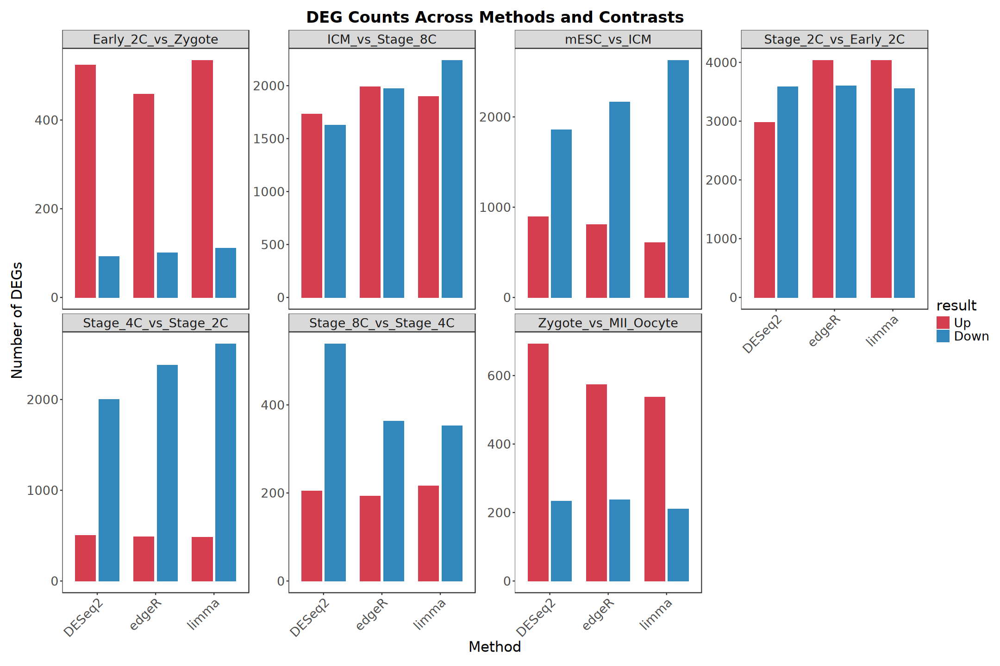

In [85]:
options(repr.plot.width = 18, repr.plot.height = 12)

all_results |> filter(result != "NS") |> 
    dplyr::count(method, contrast, result) |>
    ggplot(aes(x = method, y = n, fill = result)) +
        geom_col(position = position_dodge(width = 0.8), width = 0.7) +
        facet_wrap(~ contrast, nrow = 2, scales = "free_y") +
        scale_fill_manual(
            values = c("Up" = "#D53E4F", "Down" = "#3288BD")) +
        labs(
            title = "DEG Counts Across Methods and Contrasts", 
            x = "Method", y = "Number of DEGs") +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            strip.text = element_text(size = 16),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18), 
            axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
            axis.text.y = element_text(size = 16))

In [86]:
# ------------------------------------------------------------------------------
# Function: summarize_software_deg_overlaps
#
# Description:
# This function computes and summarizes the overlap composition of DEG sets 
# across different software packages (e.g., DESeq2, edgeR, limma) within a contrast.
# ------------------------------------------------------------------------------
summarize_software_deg_overlaps <- function(prefix, deg_list) {
    sample_names <- grep(
        paste0("^", prefix, "_"), names(deg_list), value = TRUE)
    software_id <- str_replace_all(
        sample_names, paste0(prefix, "_"), "")
    
    comb_levels <- unlist(lapply(seq_along(software_id), function(i) {
        combn(software_id, i, FUN = function(x) 
            paste(x, collapse = "&"), simplify = TRUE)
    }), use.names = FALSE)
    
    current_list <- deg_list[sample_names]
    names(current_list) <- software_id
    
    all_genes <- unique(unlist(current_list))
    
    venn_grid <- expand.grid(rep(list(c(0, 1)), length(software_id))) |> 
        set_names(software_id)
    
    counts_df <- map_dfc(current_list, ~ as.integer(all_genes %in% .x)) |> 
        group_by(across(all_of(software_id))) |> 
        summarise(Counts = n(), .groups = "drop")
    
    venn_grid |> left_join(counts_df, by = software_id) |> 
        mutate(Counts = replace_na(Counts, 0)) |> rowwise() |> 
        mutate(
            Combination = {
                vals <- c_across(all_of(software_id))
                present <- software_id[vals == 1]
                if (length(present) == 0) "none" else 
                paste(present, collapse = "&")
            } |> factor(levels = comb_levels), 
            Group = prefix) |> 
        ungroup() |> 
        filter(Combination != "none") |> 
        dplyr::select(Group, Combination, Counts) |> 
        as.data.frame()
}

In [87]:
deg_list <- all_results |> filter(result != "NS") |> 
    mutate(list_name = paste0(contrast, "_", method)) |> 
    group_by(list_name) |> 
    summarise(genes = list(gene_id)) |> 
    deframe()

deg_overlap_df <- map(contrast_labels, function(con) {
    summarize_software_deg_overlaps(prefix = con, deg_list = deg_list)}) |> 
    list_rbind()

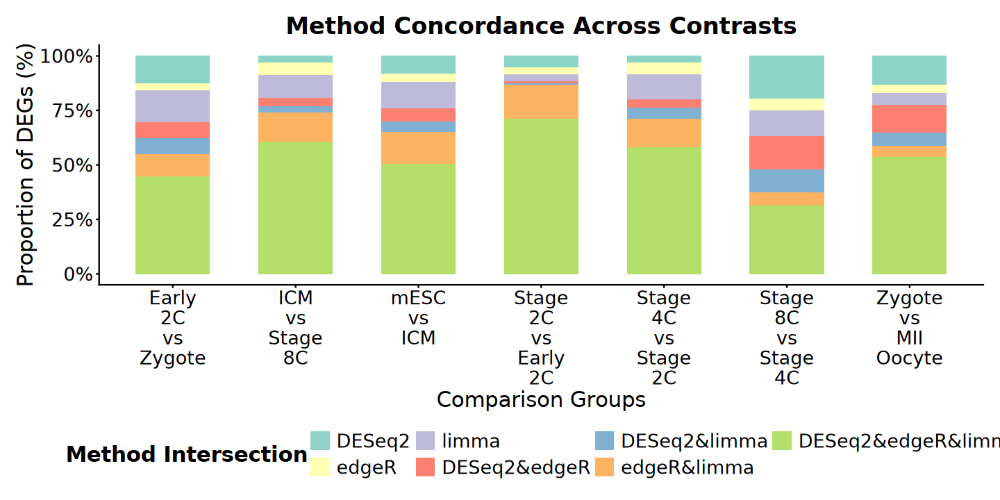

In [88]:
options(repr.plot.width = 12, repr.plot.height = 6)

deg_overlap_df |>
    mutate(Group = str_replace_all(Group, "_", "\n")) |>
    ggplot(aes(x = Group, y = Counts, fill = Combination)) +
        geom_bar(stat = "identity", position = "fill", width = 0.6) +
        scale_y_continuous(labels = scales::percent_format()) + 
        scale_fill_brewer(palette = "Set3") +
        labs(
            title = "Method Concordance Across Contrasts",
            x = "Comparison Groups", 
            y = "Proportion of DEGs (%)",
            fill = "Method Intersection"
        ) +
        theme_classic() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
            plot.margin = unit(c(1, 1, 1, 1), "line"), 
            legend.position = "bottom", 
            legend.title = element_text(size = 18, face = "bold"), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18), 
            axis.text = element_text(size = 16))

## DEGs Visualization

In [89]:
group_levels <- levels(dds$Stage)

contrast_pairs <- map2(
    group_levels[-1], group_levels[-length(group_levels)],
    ~ c(.x, .y))

contrast_labels <- contrast_pairs |>
    map_chr(~ paste0(.x[1], "_vs_", .x[2]))
contrast_labels

[1] "Zygote_vs_MIIoocyte"  "early2cell_vs_Zygote" "2cell_vs_early2cell" 
[4] "4cell_vs_2cell"       "8cell_vs_4cell"       "ICM_vs_8cell"        
[7] "mESC_vs_ICM"

### Multi-group Volcano

In [90]:
deg_df <- bind_rows(deseq2_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(deg_df$contrast, deg_df$result)

                      
                          Up  Down    NS
  Zygote_vs_MIIoocyte    693   233 18029
  early2cell_vs_Zygote   524    92 18339
  2cell_vs_early2cell   2978  3589 12388
  4cell_vs_2cell         501  2002 16452
  8cell_vs_4cell         205   539 18211
  ICM_vs_8cell          1732  1626 15597
  mESC_vs_ICM            897  1859 16199

In [91]:
max_logfc <- deg_df$logFC |> abs() |> 
    max(na.rm = TRUE) |> 
    ceiling()

min_padj <- deg_df$padj |> pmax(1e-300) |>
    (\(x) -log10(x))() |>
    max(na.rm = TRUE) |>
    (\(x) ceiling(x / 5) * 5)()

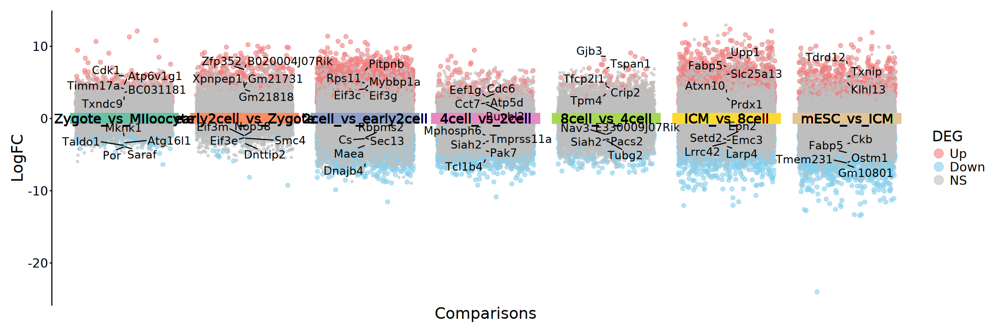

In [92]:
options(repr.plot.width = 18, repr.plot.height = 6)

ggplot(deg_df, aes(x = contrast, y = logFC)) + 
    geom_point(
        aes(color = result, size = result), 
        position = position_jitter(width = 0.4, height = 0), 
        na.rm = TRUE, alpha = 0.6) +
    geom_tile(
        aes(x = contrast, y = 0, fill = contrast), 
        width = 0.9, height = 1.5, show.legend = FALSE) +
    geom_text(
        aes(x = contrast, y = 0, label = contrast), 
        color = "black", size = 6) +
    geom_text_repel(
        aes(label = label), na.rm = TRUE, size = 5, 
        min.segment.length = 0, segment.size = 0.5,
        color = "black", max.overlaps = Inf) +
    scale_fill_brewer(palette = "Set2") + 
    scale_size_manual(
        values = c("Up" = 2, "Down" = 2, "NS" = 1),
        guide = "none") + 
    scale_color_manual(
        name = "DEG",
        values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
    guides(color = guide_legend(override.aes = list(size = 5))) +
    labs(x = "Comparisons", y = "LogFC") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 20),
        axis.text.x = element_blank(),
        axis.text.y = element_text(size = 16),
        axis.ticks.x = element_blank(),
        axis.line.x = element_blank())

### Heatmap

In [93]:
heatmap_dat <- deg_df |>
    filter(result %in% c("Up", "Down")) |>
    pull(gene_id) |>
    unique() |>
    (\(idx) norm_mat[idx, ])()

In [94]:
ar <- deg_df |> 
    dplyr::select(gene_id, contrast, DEG = result) |>
    pivot_wider(names_from = contrast, values_from = DEG) |> 
    filter(gene_id %in% rownames(heatmap_dat)) |>
    column_to_rownames("gene_id") |> 
    dplyr::select(all_of(contrast_labels))

ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Replicate, Stage)

In [95]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Stage)),
    levels(dds$Stage))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Replicate)),
    levels(dds$Replicate))
deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

anno_colors <- setNames(
    replicate(length(contrast_labels), deg_colors, simplify = FALSE),
    contrast_labels)

anno_colors <- anno_colors |> 
    append(list(
        Stage = group_colors,
        Replicate = replicate_colors))

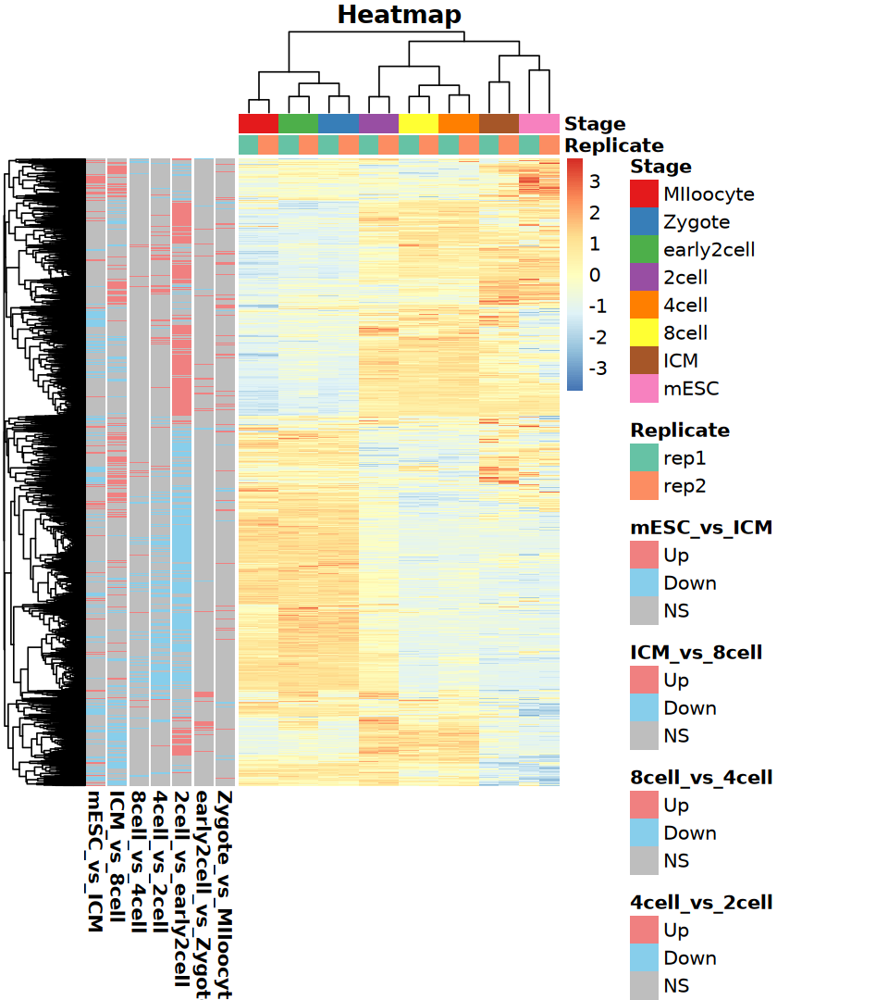

In [96]:
options(repr.plot.width = 8, repr.plot.height = 9)
pheatmap::pheatmap(
    heatmap_dat, scale = "row",
    annotation_row = ar, annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap", fontsize = 12, 
    show_colnames = FALSE, show_rownames = FALSE)

### ComplexHeatmap

In [97]:
# suppressPackageStartupMessages(library(circlize))
suppressPackageStartupMessages(library(ComplexHeatmap))

In [98]:
heatmap_dat <- deg_df |>
    filter(result %in% c("Up", "Down")) |>
    pull(gene_id) |>
    unique() |>
    (\(idx) norm_mat[idx, ])()

In [99]:
heatmap_col <- circlize::colorRamp2(
    breaks = c(-2, 0, 2), 
    colors = rev(brewer.pal(n = 3, name = "RdYlBu")))

group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Stage)),
    levels(dds$Stage))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Replicate)),
    levels(dds$Replicate))

deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

In [100]:
ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Stage, Replicate)

top_anno <- HeatmapAnnotation(
    df = ac, col = list(
        Stage = group_colors, 
        Replicate = replicate_colors))

In [101]:
ar <- deg_df |> 
    dplyr::select(gene_id, contrast, DEG = result) |>
    pivot_wider(names_from = contrast, values_from = DEG) |> 
    filter(gene_id %in% rownames(heatmap_dat)) |>
    column_to_rownames("gene_id") |> 
    dplyr::select(all_of(contrast_labels))

anno_colors <- setNames(
    replicate(length(contrast_labels), deg_colors, simplify = FALSE), 
    contrast_labels)

left_anno <- rowAnnotation(
    df = ar, col = anno_colors, show_legend = FALSE)

In [102]:
gene_labels <- deg_df |>
    dplyr::filter(!is.na(label)) |>
    dplyr::select(gene_id, label)

mark_rows <- which(rownames(heatmap_dat) %in% gene_labels$gene_id)
mark_labels <- gene_labels$label[
    match(rownames(heatmap_dat)[mark_rows], gene_labels$gene_id)]

right_anno <- rowAnnotation(
    foo = anno_mark(
        at = mark_rows,
        labels = mark_labels,
        labels_gp = gpar(fontsize = 12)))

In [103]:
lg_heatmap <- Legend(
    title = "Expression (z-score)", col_fun = heatmap_col)

lg_group <- Legend(
    title = "Stage", labels = levels(dds$Stage))

lg_replicate <- Legend(
    title = "Replicate", labels = levels(dds$Replicate))

lg_deg <- Legend(
    labels = levels(deg_df$result), title = "DEG", 
    legend_gp = gpar(fill = deg_colors))

combined_leg <- list(lg_heatmap, lg_group, lg_replicate) |>
    packLegend(direction = "vertical")

In [104]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(
        name = "Expression", col = heatmap_col,
        top_annotation = top_anno,
        left_annotation = left_anno, 
        # right_annotation = right_anno,
        show_row_names = FALSE, 
        show_column_names = FALSE, 
        use_raster = TRUE)

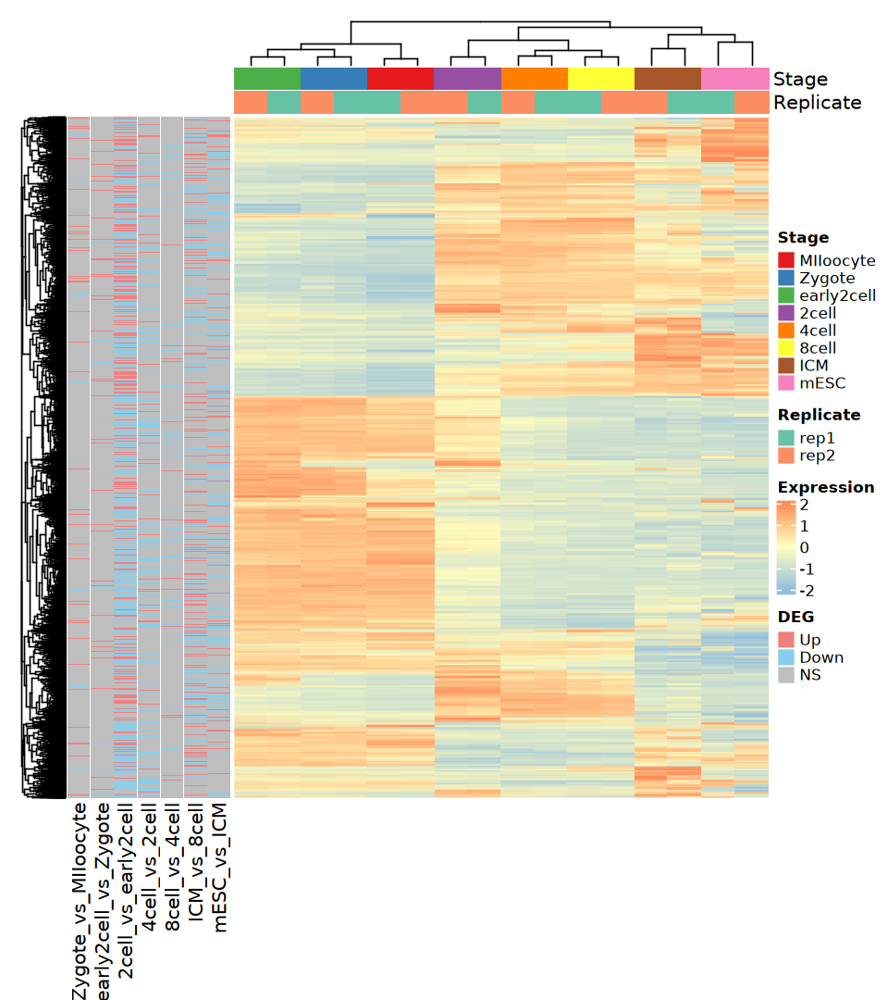

In [105]:
options(repr.plot.width = 8, repr.plot.height = 9)
draw(
    ht + combined_leg, merge_legend = TRUE, 
    annotation_legend_list = list(lg_deg), 
    legend_title_gp = gpar(fontsize = 12, fontface = "bold"), 
    legend_labels_gp = gpar(fontsize = 10), 
    padding = unit(c(5, 5, 5, 5), "mm"))

# 6. Time-course Dynamics

## 1). DEGs: Dynamic Gene Selection

### a). DESeq2 (LRT)

> The likelihood ratio test (LRT) is useful for testing multiple terms at once, for example testing 3 or more levels of a factor at once, or all interactions between two variables. The LRT for count data is conceptually similar to an analysis of variance (ANOVA) calculation in linear regression, except that in the case of the Negative Binomial GLM, we use an analysis of deviance (ANODEV), where the deviance captures the difference in likelihood between a full and a reduced model.
> - Identifies genes with significant expression dynamics across conditions. By comparing the full factors model against a reduced model, LRT filters out invariant baseline features and captures any temporal patterns  (e.g., monotonic or wave-like), serving as a crucial input for clustering.

In [106]:
design(dds)

~0 + Stage

In [107]:
dds <- DESeq(dds, test = "LRT", reduced = ~ 1)

using pre-existing size factors

estimating dispersions

found already estimated dispersions, replacing these

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [108]:
deseq2_lrt_result <- results(dds) |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < 1e-5  ~ "Sig", TRUE ~ "NS") |> 
            factor(levels = c("Sig", "NS"))) |>
    left_join(
        rowData(dds) |> as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(deseq2_lrt_result$result)
head(deseq2_lrt_result)


  Sig    NS 
11749  7206 

,baseMean,logFC,lfcSE,stat,pvalue,padj,result,symbol,type,basepairs
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>
ENSMUSG00000051951.5,5.680145,-1.6751302,1.938097,19.492727,6.776187e-03,8.742946e-03,NS,Xkr4,protein_coding,6094
ENSMUSG00000102343.1,46.309537,-1.6751324,1.568449,110.727247,6.487279e-21,2.003362e-20,Sig,Gm37381,lncRNA,1364
ENSMUSG00000025900.12,8.437849,-0.2467681,1.576099,56.580330,7.243101e-10,1.437021e-09,Sig,Rp1,protein_coding,12311
ENSMUSG00000025902.13,3.007521,0.6396330,3.379409,6.699468,4.608273e-01,4.787373e-01,NS,Sox17,protein_coding,4772
ENSMUSG00000104328.1,1.185156,-1.6751051,4.328004,2.787186,9.039667e-01,9.060221e-01,NS,Gm37323,lncRNA,2773
ENSMUSG00000098104.1,3.626701,-1.6751317,1.691926,13.011291,7.183376e-02,8.303000e-02,NS,Gm6085,processed_pseudogene,1470


### b). edgeR (ANOVA-like)

> ANOVA-like test for any differences. In edgeR, this is done by specifying multiple coefficients to glmQLFTest or glmLRT, when the design matrix includes an intercept term.

In [109]:
design <- model.matrix(~ group, data = dgel$samples)

In [110]:
dgel <- estimateDisp(dgel, design)
fit <- glmQLFit(dgel, design)
qlft <- glmQLFTest(fit, coef = 3:ncol(design))

In [111]:
edgeR_anova_result <- topTags(qlft, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < 1e-5  ~ "Sig", TRUE ~ "NS") |>
            factor(levels = c("Sig", "NS")))

table(edgeR_anova_result$result)
head(edgeR_anova_result)


  Sig    NS 
 7629 10390 

,symbol,type,basepairs,logFC.groupearly2cell,logFC.group2cell,logFC.group4cell,logFC.group8cell,logFC.groupICM,logFC.groupmESC,logCPM,F,pvalue,padj,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000099216.1,Obox8,protein_coding,1167,2.1457734,10.948572,11.367257,10.225567,-0.6430574,-4.163362,7.790136,228.1289,3.259285e-17,5.379954e-13,Sig
ENSMUSG00000049588.13,Ccdc69,protein_coding,1848,-1.8657974,-5.034992,-8.387663,-11.960794,-10.4826488,-13.847698,9.516872,289.8964,5.971424e-17,5.379954e-13,Sig
ENSMUSG00000028035.13,Dnajb4,protein_coding,8765,-0.1627962,-6.068312,-8.922233,-8.809991,-8.5954567,-12.018973,9.012110,254.2385,1.916639e-16,1.151197e-12,Sig
ENSMUSG00000041836.10,Ptpre,protein_coding,10201,-1.8128205,-4.071580,-7.600079,-8.585797,-8.3195461,-10.592096,6.398982,229.3930,3.532652e-16,1.292138e-12,Sig
ENSMUSG00000109841.2,E330011O21Rik,lncRNA,3227,-0.5619426,-4.115998,-7.513803,-8.511226,-6.6614070,-10.111900,6.835541,233.2718,3.585489e-16,1.292138e-12,Sig
ENSMUSG00000050234.7,Gja4,protein_coding,1685,0.6416168,-5.001586,-7.899469,-6.872575,-5.3952189,-8.567357,5.455710,189.6925,4.545540e-16,1.333518e-12,Sig


In [112]:
comparison_df <- deseq2_lrt_result |> 
    rownames_to_column("gene_id") |>
    dplyr::select(gene_id, result_deseq2 = result) |> 
    inner_join(
        edgeR_anova_result |> 
            rownames_to_column("gene_id") |>
            dplyr::select(gene_id, result_edger = result),
        by = c("gene_id"))

cat("\n=========================================\n")
cat("Contrast:", "Stages", "\n")
cat("=========================================\n")
print(table(
    DESeq2 = comparison_df$result_deseq2, 
    edgeR = comparison_df$result_edger))


Contrast: Stages 
      edgeR
DESeq2  Sig   NS
   Sig 7557 4192
   NS    71 6027


## 2). Trend Clustering

> It is recommended to use genes with significant differential expression to enhance computational efficiency. Of course, all genes can also be selected for cluster analysis.

In [113]:
sig_gene_ids <- deseq2_lrt_result |> 
    dplyr::filter(result == "Sig") |> rownames()

message(
    "Number of time-significantly dynamic genes identified by LRT:", 
    length(sig_gene_ids), "\n")

Number of time-significantly dynamic genes identified by LRT:11749




In [114]:
norm_tpm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs, FUN = "/") |>
    (\(rpk) sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6)()
norm_ltpm <- log2(norm_tpm + 1)
norm_mat <- norm_ltpm[sig_gene_ids, ]

# rld_mat <- assay(rlog(dds, blind = FALSE))
# vst_mat <- assay(vst(dds, blind = FALSE))
# norm_mat <- vst_mat[sig_gene_ids, ]

In [115]:
stages <- eSet$Stage

norm_mean_mat <- sapply(stage_levels, function(stage) {
    rowMeans(norm_mat[, stages == stage, drop = FALSE])
})

print(dim(norm_mean_mat))
print(head(norm_mean_mat))

[1] 11749     8


                      MIIoocyte    Zygote early2cell    2cell     4cell
ENSMUSG00000102343.1  5.2606613 5.1917083  4.6050879 2.747627 0.3252063
ENSMUSG00000025900.12 0.4765123 0.9656289  0.6931123 0.101324 0.0000000
ENSMUSG00000033845.13 1.0700131 2.2757085  2.0843211 4.292292 5.8094164
ENSMUSG00000025903.14 5.6377777 6.6014301  6.0299232 5.568798 5.6586135
ENSMUSG00000033813.15 8.9230783 8.8739465  8.7242819 8.294976 8.2058738
ENSMUSG00000062588.4  3.5099042 3.0589458  3.2612740 5.789049 4.8558665
                          8cell       ICM       mESC
ENSMUSG00000102343.1  0.3876449 1.3120312 0.00000000
ENSMUSG00000025900.12 0.0000000 0.1345323 0.04065711
ENSMUSG00000033845.13 6.1500446 6.9139439 7.88988235
ENSMUSG00000025903.14 6.4131220 6.5621355 7.22248248
ENSMUSG00000033813.15 7.9673264 7.1829511 8.38275503
ENSMUSG00000062588.4  4.9742227 1.7011939 0.56340792


### a). Mfuzz

> Soft clustering: fuzzy c-means algorithm (of the e1071 package) based on minimization of a weighted square error function.

In [116]:
suppressPackageStartupMessages(library(Mfuzz))

Warning message:
"no DISPLAY variable so Tk is not available"


In [117]:
# Filtering of genes based on their standard deviation
cl_eset <- ExpressionSet(assayData = norm_mean_mat) |>
    filter.std(min.std = 0.5, visu = FALSE) |>
    standardise()
cl_eset

143 genes excluded.


ExpressionSet (storageMode: lockedEnvironment)
assayData: 11606 features, 8 samples 
  element names: exprs 
protocolData: none
phenoData: none
featureData: none
experimentData: use 'experimentData(object)'
Annotation:  

In [118]:
# Estimate for optimal fuzzifier m
m_val <- mestimate(cl_eset)
message(paste0("fuzzifier m: ", m_val))

set.seed(123)
cl_mfuzz <- mfuzz(cl_eset, c = 9, m = m_val)
cl_mfuzz$cluster |> table()

fuzzifier m: 1.43392421465525




   1    2    3    4    5    6    7    8    9 
 999  748 2161 1172 1638  875 1276 1006 1731 

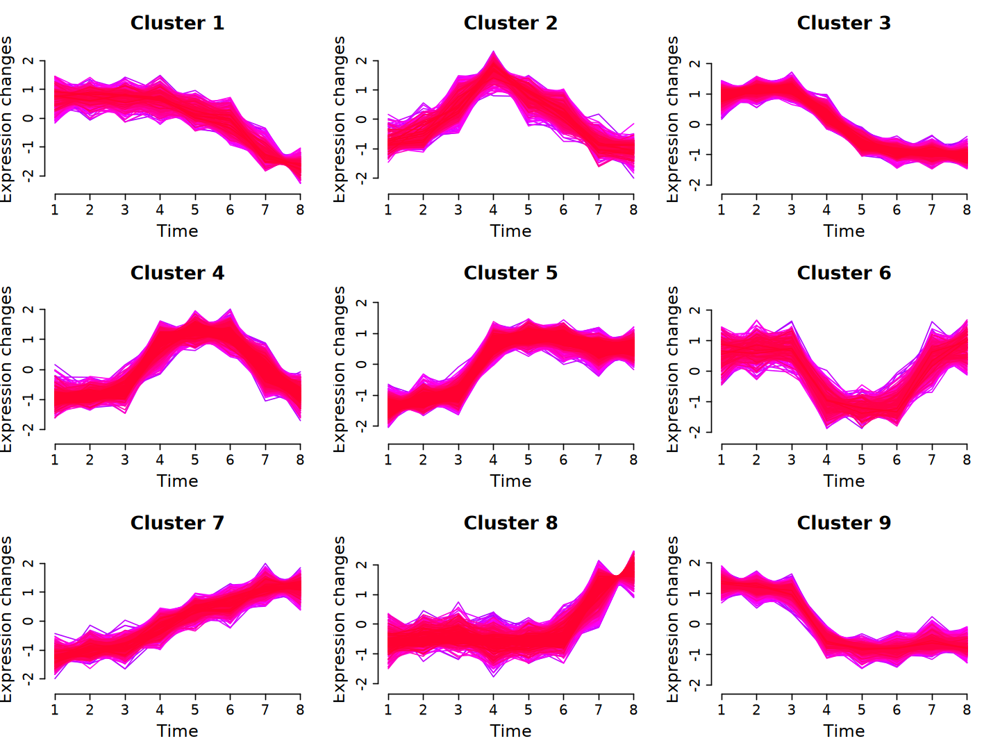

In [119]:
options(repr.plot.width = 12, repr.plot.height = 9)

mfuzz.plot2(
    cl_eset, cl = cl_mfuzz, mfrow = c(3, 3), 
    min.mem = 0.8, x11 = FALSE, cex.main = 2,
    cex.lab = 1.8, cex.axis = 1.5)

### b). TCseq

In [120]:
suppressPackageStartupMessages(library(TCseq))

Warning message:
"replacing previous import 'e1071::element' by 'ggplot2::element' when loading 'TCseq'"


In [121]:
norm_mean_filtered_tpm <- norm_mean_mat[rowSds(norm_mean_mat) >= 0.5, ]

set.seed(123)
cl_tcseq <- timeclust(
    norm_mean_filtered_tpm, algo = "cm", k = 9, standardize = TRUE)
cl_tcseq@cluster |> table()


   1    2    3    4    5    6    7    8    9 
1768 1170 1128 1356 1048 1137 1157 1211 1631 

Warning message:
"The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the TCseq package.
  Please report the issue to the authors."


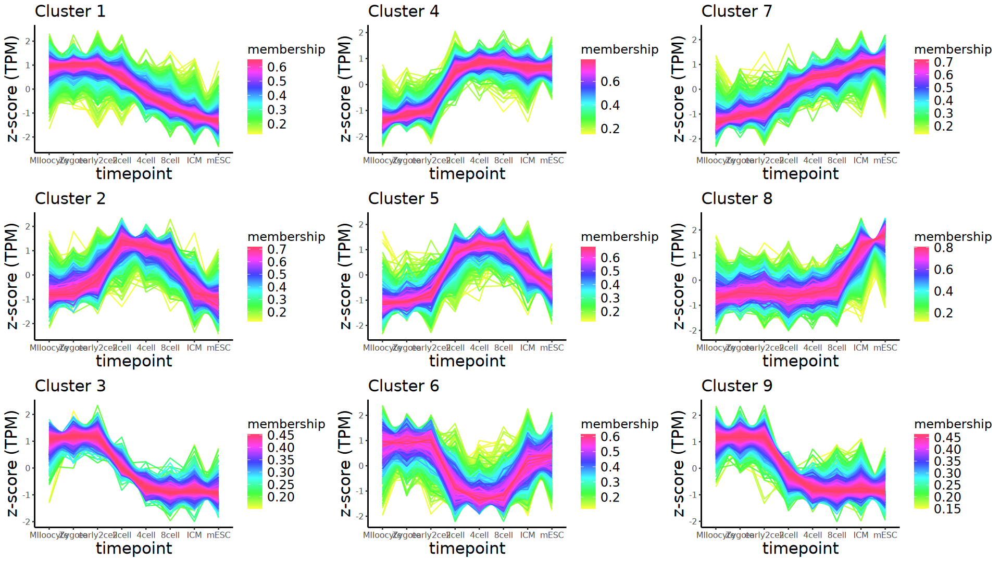

In [122]:
options(repr.plot.width = 16, repr.plot.height = 9)

p <- timeclustplot(
    cl_tcseq, value = "z-score (TPM)", cols = 3, axis.text.size = 9)

### [TiSA](https://github.com/Ylefol/TimeSeriesAnalysis)?

PART clustering

- Yohan Lefol, Tom Korfage, Robin Mjelle, Christian Prebensen, Torben Lüders, Bruno Müller, Hans Krokan, Antonio Sarno, Lene Alsøe, CONSORTIUM LEMONAID, Jan-Erik Berdal, Pål Sætrom, Hilde Nilsen, Diana Domanska, TiSA: TimeSeriesAnalysis—a pipeline for the analysis of longitudinal transcriptomics data, NAR Genomics and Bioinformatics, Volume 5, Issue 1, March 2023, lqad020, https://doi.org/10.1093/nargab/lqad020.

## 3). Regression

### a). maSigPro

> maSigPro follows a two-step regression strategy to find genes with significant temporal expression changes and significant differences between experimental groups.

In [123]:
suppressPackageStartupMessages(library(maSigPro))

In [124]:
design_df <- colData(eSet) |> as.data.frame() |> 
    mutate(
        Time = as.integer(Stage), 
        Replicate = as.integer(Replicate), 
        Group = 1) |> 
    dplyr::select(Time, Replicate, Group) |>
    arrange(Time, Replicate)

head(design_df)

,Time,Replicate,Group
,<int>,<int>,<dbl>
MIIoocyte_rep1,1,1,1
MIIoocyte_rep2,1,2,1
Zygote_rep1,2,1,1
Zygote_rep2,2,2,1
early2cell_rep1,3,1,1
early2cell_rep2,3,2,1


In [125]:
# Defining the regression model
# degree = time points - 1
# Usually, a polynomial of degree 2 is more than enough to model the gene expression, 
# although a degree 3 may be appropriate in experacimental setups with a big number of
# time points.
design <- make.design.matrix(design_df, degree = 3)

In [126]:
# dgel <- estimateGLMCommonDisp(dgel, design = design)
# phi <- dgel$common.dispersion
# theta <- 1/phi
1 / dgel$common.dispersion

[1] 5.515119

In [127]:
# DEseq2
# norm_counts <- counts(dds, normalized = TRUE)

# # edgeR
# eff_lib_size <- dgel$samples$lib.size * dgel$samples$norm.factors
# norm_counts <- t(t(dgel$counts) / eff_lib_size) * mean(eff_lib_size)

# TPM
norm_counts <- norm_ltpm

In [128]:
# Performs regression analysis for each gene to identify significant ones.
fit <- p.vector(
    norm_counts, design, counts = TRUE, 
    theta = 6, Q = 0.05, MT.adjust = "BH")

[1] "fitting  gene 100 out of 18955"
[1] "fitting  gene 200 out of 18955"
[1] "fitting  gene 300 out of 18955"
[1] "fitting  gene 400 out of 18955"
[1] "fitting  gene 500 out of 18955"
[1] "fitting  gene 600 out of 18955"
[1] "fitting  gene 700 out of 18955"
[1] "fitting  gene 800 out of 18955"
[1] "fitting  gene 900 out of 18955"
[1] "fitting  gene 1000 out of 18955"
[1] "fitting  gene 1100 out of 18955"
[1] "fitting  gene 1200 out of 18955"
[1] "fitting  gene 1300 out of 18955"
[1] "fitting  gene 1400 out of 18955"
[1] "fitting  gene 1500 out of 18955"
[1] "fitting  gene 1600 out of 18955"
[1] "fitting  gene 1700 out of 18955"
[1] "fitting  gene 1800 out of 18955"
[1] "fitting  gene 1900 out of 18955"
[1] "fitting  gene 2000 out of 18955"
[1] "fitting  gene 2100 out of 18955"
[1] "fitting  gene 2200 out of 18955"
[1] "fitting  gene 2300 out of 18955"
[1] "fitting  gene 2400 out of 18955"
[1] "fitting  gene 2500 out of 18955"
[1] "fitting  gene 2600 out of 18955"
[1] "fitting  gene 27

In [129]:
print(fit$i)

[1] 16321


In [130]:
# Selects the best regression model for each gene using stepwise regression.
tstep <- T.fit(fit, step.method = "backward", alfa = 0.05)

[1] "fitting  gene 100 out of 16321"
[1] "fitting  gene 200 out of 16321"
[1] "fitting  gene 300 out of 16321"
[1] "fitting  gene 400 out of 16321"
[1] "fitting  gene 500 out of 16321"
[1] "fitting  gene 600 out of 16321"
[1] "fitting  gene 700 out of 16321"
[1] "fitting  gene 800 out of 16321"
[1] "fitting  gene 900 out of 16321"
[1] "fitting  gene 1000 out of 16321"
[1] "fitting  gene 1100 out of 16321"
[1] "fitting  gene 1200 out of 16321"
[1] "fitting  gene 1300 out of 16321"
[1] "fitting  gene 1400 out of 16321"
[1] "fitting  gene 1500 out of 16321"
[1] "fitting  gene 1600 out of 16321"
[1] "fitting  gene 1700 out of 16321"
[1] "fitting  gene 1800 out of 16321"
[1] "fitting  gene 1900 out of 16321"
[1] "fitting  gene 2000 out of 16321"
[1] "fitting  gene 2100 out of 16321"
[1] "fitting  gene 2200 out of 16321"
[1] "fitting  gene 2300 out of 16321"
[1] "fitting  gene 2400 out of 16321"
[1] "fitting  gene 2500 out of 16321"
[1] "fitting  gene 2600 out of 16321"
[1] "fitting  gene 27

In [131]:
sigs <- get.siggenes(tstep, rsq = 0.6, vars = "all")

In [132]:
summary(sigs)
sig_gene_ids <- sigs$summary

cat("Number of significant time-varying genes:", length(sig_gene_ids), "\n")

          Length Class  Mode     
sig.genes     7  -none- list     
summary   10113  -none- character

Number of significant time-varying genes: 10113 


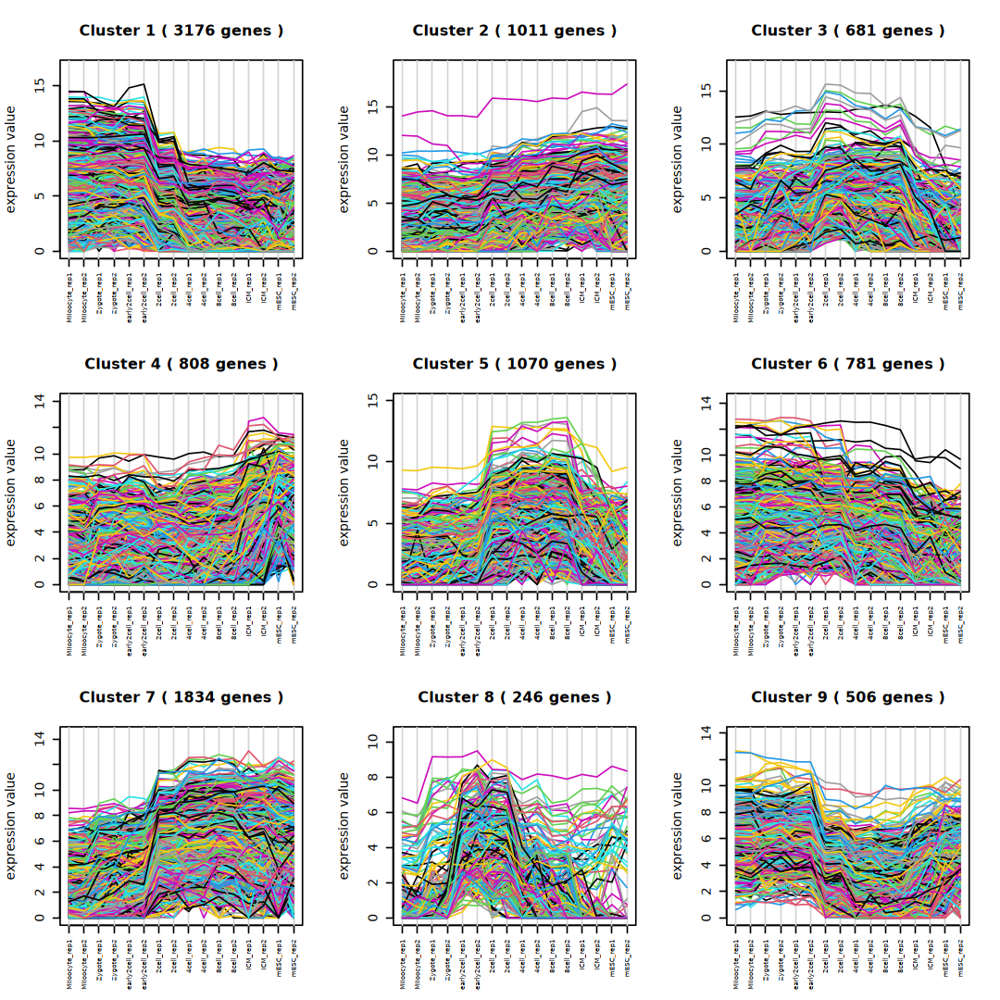

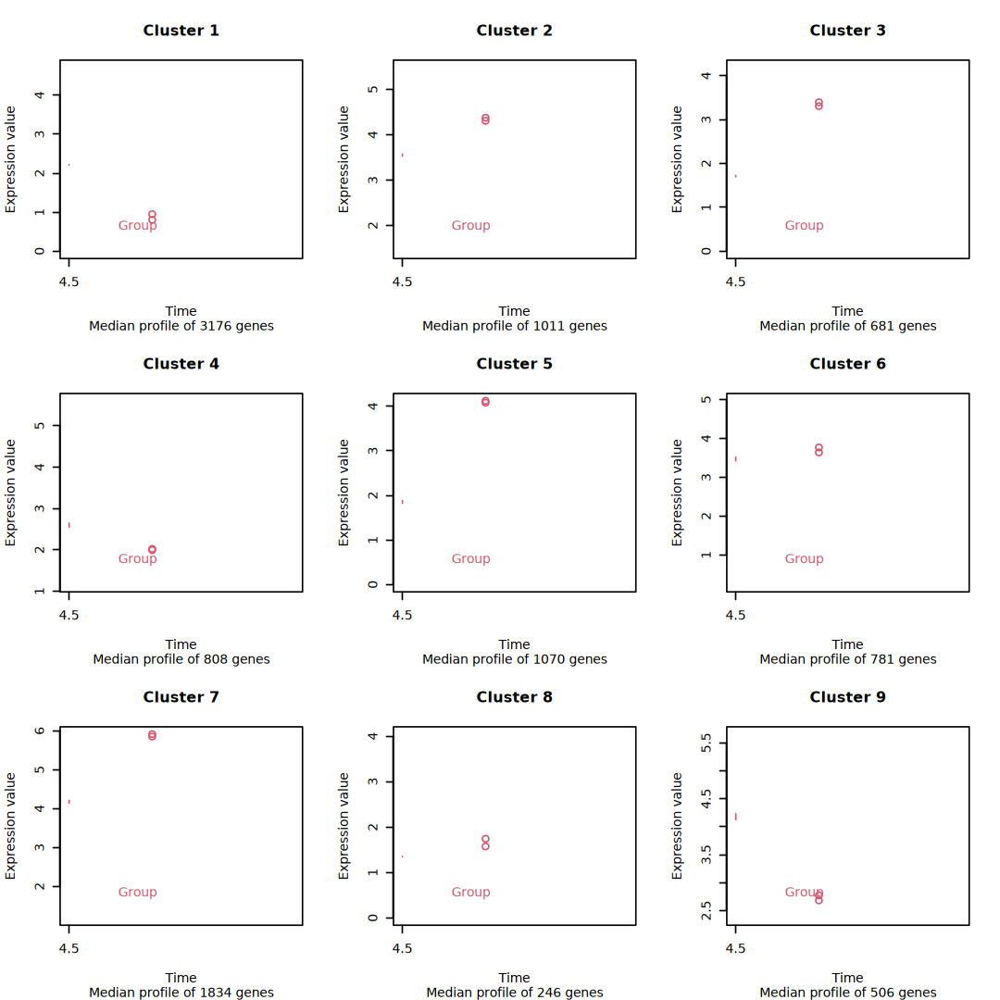

In [133]:
options(repr.plot.width = 9, repr.plot.height = 9)
cl_masigpro <- see.genes(sigs$sig.genes, k = 9)

In [134]:
cl_masigpro$cut |> table()


   1    2    3    4    5    6    7    8    9 
3176 1011  681  808 1070  781 1834  246  506 

## 4). WGCNA

## 5). Impulse Model

### ImpulseDE2?
- David S Fischer, Fabian J Theis, Nir Yosef, Impulse model-based differential expression analysis of time course sequencing data, Nucleic Acids Research, Volume 46, Issue 20, 16 November 2018, Page e119, https://doi.org/10.1093/nar/gky675.

In [135]:
# library(ImpulseDE2)
# # inputData: data.frame(sample, time, condition), raw counts矩阵
# res <- runImpulseDE2(matCount = counts, dfAnnotation = meta,
#                     boolCaseCtrl = FALSE, scaNProc = 4)
# head(res$vecDEGene)

## Clustering Evaluation

### Adjusted Rand Index, ARI

In [136]:
suppressPackageStartupMessages(library(mclust))

In [137]:
gene_lists <- list(
    names(cl_mfuzz$cluster),
    names(cl_tcseq@cluster),
    names(cl_masigpro$cut))

common_genes <- Reduce(intersect, gene_lists)

vector_mfuzz    <- cl_mfuzz$cluster[common_genes]
vector_tcseq    <- cl_tcseq@cluster[common_genes]
vector_masigpro <- cl_masigpro$cut[common_genes]

In [138]:
ari_mfuzz_tcseq    <- adjustedRandIndex(vector_mfuzz, vector_tcseq)
ari_mfuzz_masigpro <- adjustedRandIndex(vector_mfuzz, vector_masigpro)
ari_tcseq_masigpro <- adjustedRandIndex(vector_tcseq, vector_masigpro)

cat("ARI (Mfuzz vs tcseq):", ari_mfuzz_tcseq, "\n")
cat("ARI (Mfuzz vs maSigPro):", ari_mfuzz_masigpro, "\n")
cat("ARI (tcseq vs maSigPro):", ari_tcseq_masigpro, "\n")

ARI (Mfuzz vs tcseq): 0.6305267 
ARI (Mfuzz vs maSigPro): 0.5657772 
ARI (tcseq vs maSigPro): 0.4392322 


### Jaccard Similarity

In [139]:
table_match <- table(vector_mfuzz, vector_tcseq)

jaccard_matrix <- matrix(
    0, nrow=nrow(table_match), ncol=ncol(table_match),
    dimnames=list(
        paste0("Mfuzz_C", rownames(table_match)), 
        paste0("TCseq_C", colnames(table_match))))

for(i in 1:nrow(table_match)) {
    for(j in 1:ncol(table_match)) {
        intersection <- table_match[i, j]
        union_size <- sum(vector_mfuzz == rownames(table_match)[i]) + 
            sum(vector_tcseq == colnames(table_match)[j]) - intersection
        jaccard_matrix[i, j] <- intersection / union_size
    }
}

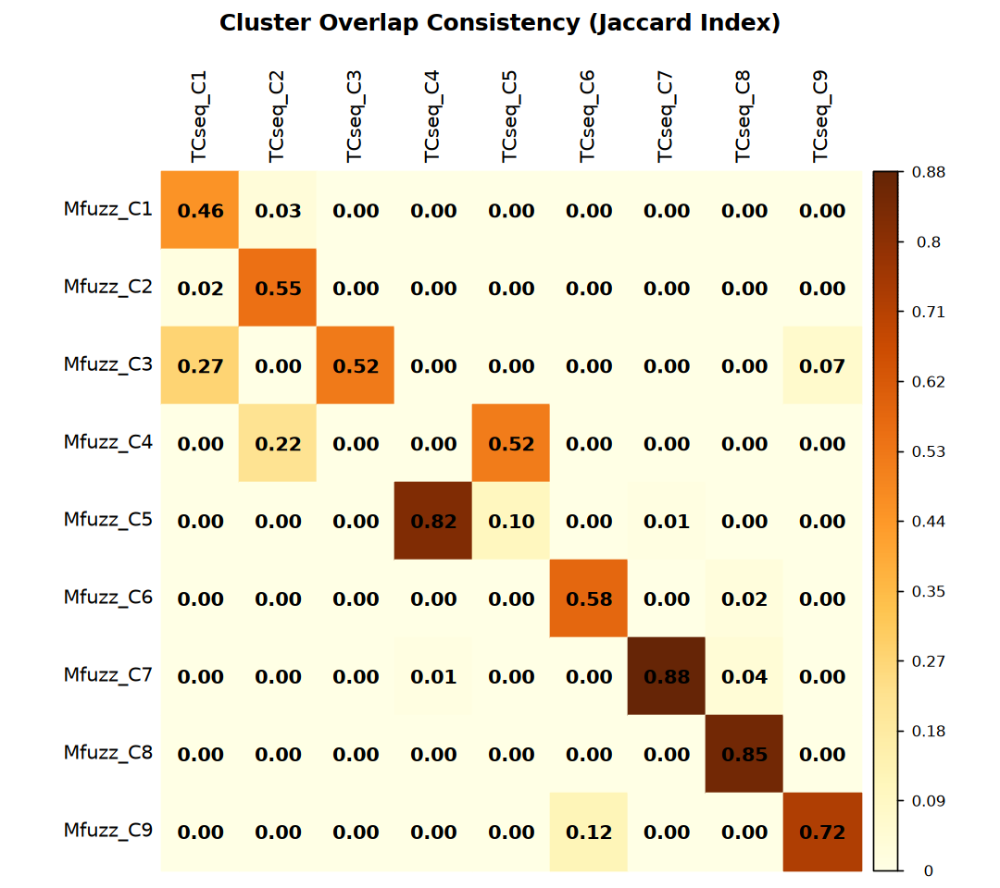

In [140]:
options(repr.plot.width = 9, repr.plot.height = 8)
corrplot::corrplot(
    jaccard_matrix, is.corr = FALSE, method = "color", 
    addCoef.col = "black", tl.col = "black", 
    title = "Cluster Overlap Consistency (Jaccard Index)", 
    mar = c(0,0,2,0))

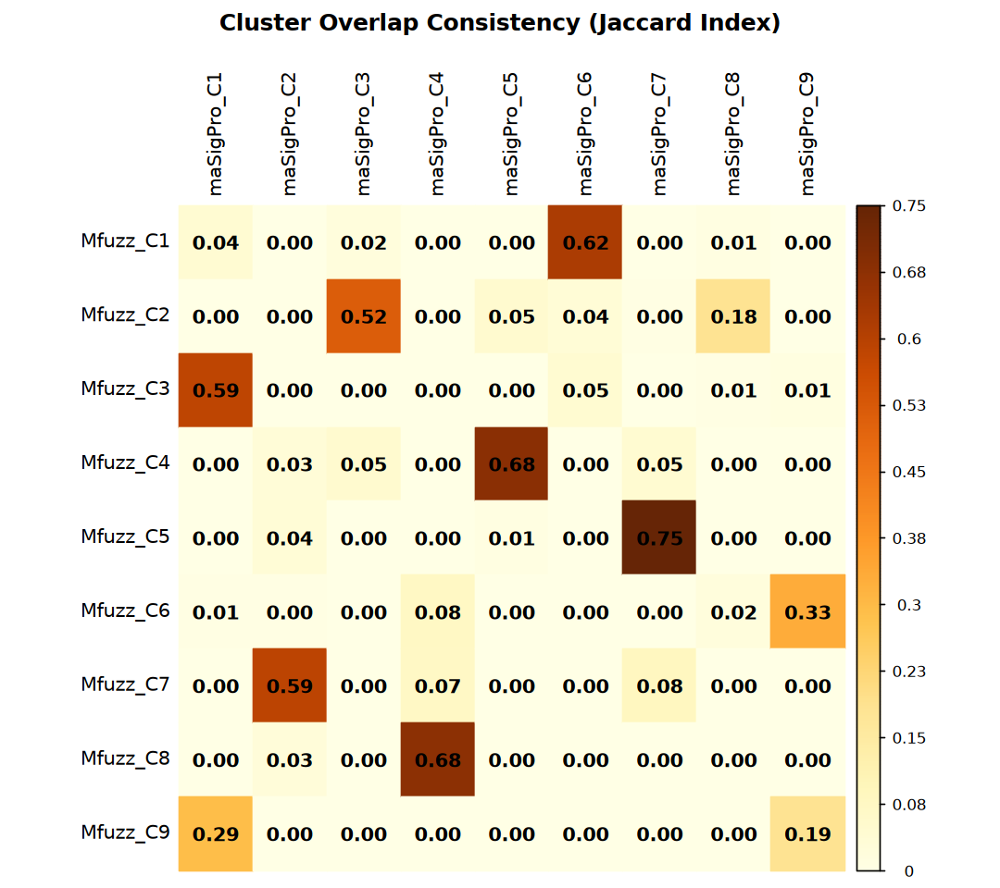

In [141]:
table_match <- table(vector_mfuzz, vector_masigpro)

jaccard_matrix <- matrix(
    0, nrow=nrow(table_match), ncol=ncol(table_match),
    dimnames=list(
        paste0("Mfuzz_C", rownames(table_match)), 
        paste0("maSigPro_C", colnames(table_match))))

for(i in 1:nrow(table_match)) {
    for(j in 1:ncol(table_match)) {
        intersection <- table_match[i, j]
        union_size <- sum(vector_mfuzz == rownames(table_match)[i]) + 
            sum(vector_masigpro == colnames(table_match)[j]) - intersection
        jaccard_matrix[i, j] <- intersection / union_size
    }
}

options(repr.plot.width = 9, repr.plot.height = 8)
corrplot::corrplot(
    jaccard_matrix, is.corr = FALSE, method = "color", 
    addCoef.col = "black", tl.col = "black", 
    title = "Cluster Overlap Consistency (Jaccard Index)", 
    mar = c(0,0,2,0))

## Clustering Visualization

### Lineplot

In [142]:
norm_mat <- log2(tpm + 1)

In [143]:
norm_expr_df <- norm_mat |> as.data.frame() |>
    rownames_to_column(var = "gene_id") |>
    pivot_longer(cols = -gene_id, names_to = "sample", values_to = "value")

In [144]:
plot_lineplot <- function(cluster, expression, coldata, group, method) {
    data.frame(cluster = cluster) |>
        rownames_to_column(var = "gene_id") |>
        mutate(cluster = factor(paste0("cluster", cluster))) |>
        add_count(cluster, name = "count") |>
        left_join(expression, by = "gene_id") |>
        left_join(coldata, by = "sample") |>
        group_by(across(all_of(group)), Replicate, cluster, count) |>
        summarize(
            median_value = median(value, na.rm = TRUE), 
            .groups = "drop") |>
        mutate(
            cluster_label = paste0(cluster, " (n=", count, ")"),
            cluster_label = factor(cluster_label)) |>
        ungroup() |>
    ggplot(aes(x = .data[[group]], y = median_value)) +
        # geom_point(position = position_jitter(width = 0.1), alpha = 0.7) + 
        stat_summary(
            aes(color = cluster_label, group = cluster_label), 
            fun = mean, geom = "line", linewidth = 1, alpha = 0.8) +
        stat_summary(
            aes(color = cluster_label, group = cluster_label), 
            fun.data = mean_se, geom = "errorbar", width = 0.1) +
        scale_x_discrete(expand = expansion(mult = c(0.1, 0.1))) +
        scale_y_continuous(expand = expansion(mult = c(0.1, 0.1))) +
        scale_color_brewer(palette = "Set3") +
        labs(
            title = paste0("Time-course: ", method), 
            color = "Cluster", x = NULL, y = "Median Expression") +
        theme_classic() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            axis.title = element_text(size = 18), 
            axis.text = element_text(size = 16),
            legend.title = element_text(size = 18),
            legend.text = element_text(size = 16))
}

In [145]:
coldata <- colData(eSet) |> as.data.frame() |> 
    rownames_to_column(var = "sample")

p1 <- plot_lineplot(
    cluster = cl_mfuzz$cluster, expression = norm_expr_df, 
    coldata = coldata, group = "Stage", method = "Mfuzz")
p2 <- plot_lineplot(
    cluster = cl_tcseq@cluster, expression = norm_expr_df, 
    coldata = coldata, group = "Stage", method = "TCseq")
p3 <- plot_lineplot(
    cluster = cl_masigpro$cut, expression = norm_expr_df, 
    coldata = coldata, group = "Stage", method = "maSigPro")

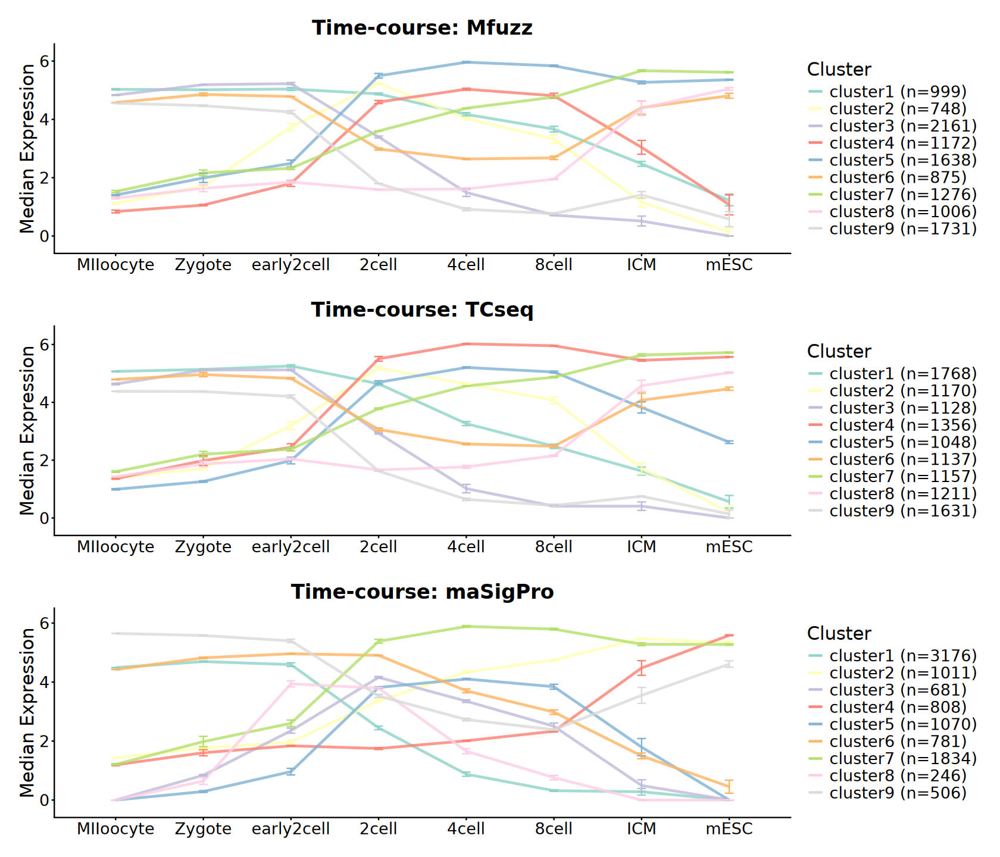

In [146]:
options(repr.plot.width = 14, repr.plot.height = 12)
p1 / p2 / p3

### Heatmap

In [147]:
ac <- colData(dds) |> 
    as.data.frame() |>
    dplyr::select(Replicate, Stage)

In [148]:
ar <- cl_mfuzz$cluster |> data.frame(Cluster = _) |>
    mutate(Cluster = factor(paste0("cluster", Cluster))) |>
    arrange(Cluster)

In [149]:
heatmap_dat <- norm_mat[rownames(ar), ]

In [150]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Stage)),
    levels(dds$Stage))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Replicate)),
    levels(dds$Replicate))
cluster_colors <- setNames(
    scales::brewer_pal(palette = "Set3")(nlevels(ar$Cluster)),
    levels(ar$Cluster))

anno_colors <- list(
    Stage = group_colors,
    Replicate = replicate_colors,
    Cluster = cluster_colors)

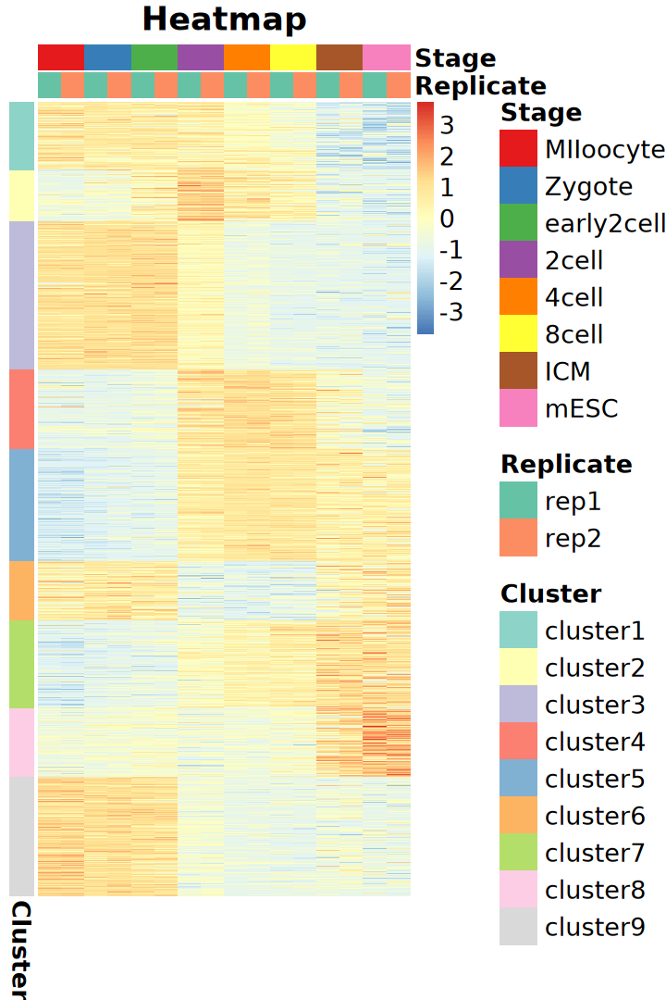

In [151]:
options(repr.plot.width = 6, repr.plot.height = 9)
pheatmap::pheatmap(
    heatmap_dat, scale = "row", 
    cluster_rows = FALSE, cluster_cols = FALSE,
    annotation_row = ar, annotation_col = ac,
    annotation_colors = anno_colors,
    main = "Heatmap", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

# 7. Gene Function Analysis

## 1). ORA

> Over-Representation Analysis

### Part 1

In [152]:
suppressPackageStartupMessages(library(org.Mm.eg.db))
suppressPackageStartupMessages(library(clusterProfiler))

In [153]:
add_ENTREZID <- function(
    res, col, orgdb, fromType = "SYMBOL", toType = "ENTREZID", 
    ignoreVersion = FALSE) {
    
    gene_ids <- res[[col]]

    if(fromType == "ENSEMBL" & ignoreVersion) {
        gene_ids <- sub("\\..*$", "", gene_ids)
    }

    gene_map <- clusterProfiler::bitr(
        gene_ids, OrgDb = orgdb, drop = FALSE, 
        fromType = fromType, toType = toType)
    
    idx <- match(gene_ids, gene_map[[fromType]])

    for (col in toType) {
        res[[col]] <- gene_map[[col]][idx]
    }
    
    return(res)
}

In [154]:
deg_df <- bind_rows(deseq2_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(deg_df$contrast, deg_df$result)

                      
                          Up  Down    NS
  Zygote_vs_MIIoocyte    693   233 18029
  early2cell_vs_Zygote   524    92 18339
  2cell_vs_early2cell   2978  3589 12388
  4cell_vs_2cell         501  2002 16452
  8cell_vs_4cell         205   539 18211
  ICM_vs_8cell          1732  1626 15597
  mESC_vs_ICM            897  1859 16199

In [155]:
deg_df <- add_ENTREZID(
    deg_df, "gene_id", org.Mm.eg.db, fromType = "ENSEMBL", 
    toType = c("SYMBOL", "ENTREZID"), ignoreVersion = TRUE)

'select()' returned 1:many mapping between keys and columns

Warning message in clusterProfiler::bitr(gene_ids, OrgDb = orgdb, drop = FALSE, :
"15.1% of input gene IDs are fail to map..."


In [156]:
head(deg_df)

gene_id,baseMean,logFC,lfcSE,stat,pvalue,padj,method,contrast,result,symbol,type,basepairs,label,SYMBOL,ENTREZID
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<fct>,<fct>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>
ENSMUSG00000005683.8,3490.3482,-2.790174,0.1210646,-23.04699,1.576913e-117,2.873135e-113,DESeq2,2cell_vs_early2cell,Down,Cs,protein_coding,5779,Cs,Cs,12974
ENSMUSG00000070319.6,1663.3813,4.033516,0.1770660,22.77973,7.283216e-115,6.635010e-111,DESeq2,2cell_vs_early2cell,Up,Eif3g,protein_coding,1984,Eif3g,Eif3g,53356
ENSMUSG00000044791.16,1261.1772,-2.916933,0.1281705,-22.75822,1.189721e-114,2.123889e-110,DESeq2,ICM_vs_8cell,Down,Setd2,protein_coding,10754,Setd2,Setd2,235626
ENSMUSG00000050017.11,761.4094,6.590448,0.3112460,21.17440,1.644622e-99,9.988340e-96,DESeq2,2cell_vs_early2cell,Up,Pitpnb,protein_coding,3377,Pitpnb,Pitpnb,56305
ENSMUSG00000003429.11,4578.1931,4.892010,0.2327298,21.02013,4.292531e-98,1.955248e-94,DESeq2,2cell_vs_early2cell,Up,Rps11,protein_coding,865,Rps11,Rps11,27207
ENSMUSG00000030738.11,1648.7241,4.095221,0.1954977,20.94767,1.970307e-97,7.179799e-94,DESeq2,2cell_vs_early2cell,Up,Eif3c,protein_coding,3511,Eif3c,Eif3c,56347


In [157]:
deg_types <- c("Up", "Down")

genes_list <- crossing(comp = contrast_labels, deg = deg_types) |>
    pmap(~ deg_df$symbol[deg_df$result == .y & deg_df$contrast == .x]) |>
    set_names(paste(
        contrast_labels, rep(deg_types, each = length(contrast_labels)), 
        sep = "_")) |>
    lapply(unique)

In [158]:
ego_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichGO, 
    universe = unique(deg_df$SYMBOL), 
    OrgDb = org.Mm.eg.db, ont = "ALL", 
    keyType = 'SYMBOL', pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500, readable = TRUE)

In [159]:
ego_compare |> dplyr::select(-one_of("geneID")) |> head()

,Cluster,ONTOLOGY,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,Zygote_vs_MIIoocyte_Up,BP,GO:0090596,sensory organ morphogenesis,79/2797,240/14305,0.3291667,1.683493,5.264349,5.669558e-07,3.186291e-03,2.957719e-03,79
2,early2cell_vs_Zygote_Up,BP,GO:0042254,ribosome biogenesis,167/2158,308/14305,0.5422078,3.594199,19.399083,9.946378e-59,5.289484e-55,5.289484e-55,167
3,early2cell_vs_Zygote_Up,BP,GO:0022613,ribonucleoprotein complex biogenesis,203/2158,438/14305,0.4634703,3.072263,18.565667,1.817078e-56,4.831610e-53,4.831610e-53,203
4,early2cell_vs_Zygote_Up,BP,GO:0006364,rRNA processing,112/2158,211/14305,0.5308057,3.518617,15.534818,2.240314e-38,3.971329e-35,3.971329e-35,112
5,early2cell_vs_Zygote_Up,BP,GO:0002181,cytoplasmic translation,104/2158,197/14305,0.5279188,3.499480,14.889154,1.999234e-35,2.657982e-32,2.657982e-32,104
6,early2cell_vs_Zygote_Up,BP,GO:0016072,rRNA metabolic process,118/2158,246/14305,0.4796748,3.179679,14.534594,8.956715e-35,9.526362e-32,9.526362e-32,118


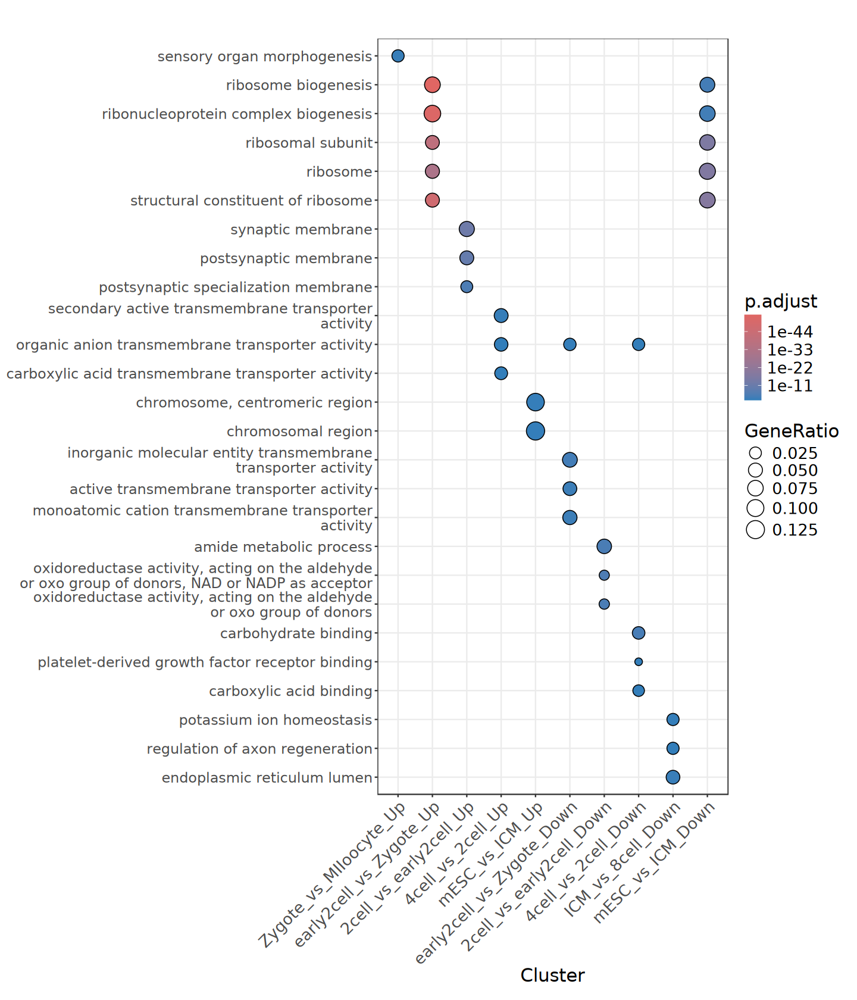

In [160]:
options(repr.plot.width = 12, repr.plot.height = 14)

dotplot(ego_compare, showCategory = 3, label_format = 50) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

In [161]:
deg_types <- c("Up", "Down")

genes_list <- crossing(comp = contrast_labels, deg = deg_types) |>
    pmap(~ deg_df$ENTREZID[deg_df$result == .y & deg_df$contrast == .x]) |>
    set_names(paste(
        contrast_labels, rep(deg_types, each = length(contrast_labels)), 
        sep = "_")) |>
    lapply(unique)

In [162]:
ekegg_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichKEGG, 
    universe = unique(deg_df$ENTREZID), 
    organism = "mmu", pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500)

In [163]:
ekegg_compare |> dplyr::select(-one_of("geneID")) |> head()

,Cluster,category,subcategory,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,early2cell_vs_Zygote_Up,Genetic Information Processing,Translation,mmu03010,Ribosome,115/989,181/6380,0.6353591,4.098677,18.113172,2.605082e-50,8.961480e-48,8.528214e-48,115
2,early2cell_vs_Zygote_Up,Human Diseases,Infectious disease: viral,mmu05171,Coronavirus disease,98/989,200/6380,0.4900000,3.160971,13.298707,1.021827e-29,1.757543e-27,1.672570e-27,98
3,early2cell_vs_Zygote_Up,Organismal Systems,Environmental adaptation,mmu04714,Thermogenesis,61/989,212/6380,0.2877358,1.856173,5.429963,4.351834e-07,4.990103e-05,4.748844e-05,61
4,early2cell_vs_Zygote_Up,Metabolism,Energy metabolism,mmu00190,Oxidative phosphorylation,41/989,128/6380,0.3203125,2.066323,5.219443,1.836216e-06,1.359542e-04,1.293811e-04,41
5,early2cell_vs_Zygote_Up,Human Diseases,Neurodegenerative disease,mmu05012,Parkinson disease,66/989,245/6380,0.2693878,1.737810,5.043824,1.976079e-06,1.359542e-04,1.293811e-04,66
6,early2cell_vs_Zygote_Up,Human Diseases,Neurodegenerative disease,mmu05020,Prion disease,62/989,238/6380,0.2605042,1.680502,4.582505,1.306817e-05,7.492416e-04,7.130175e-04,62


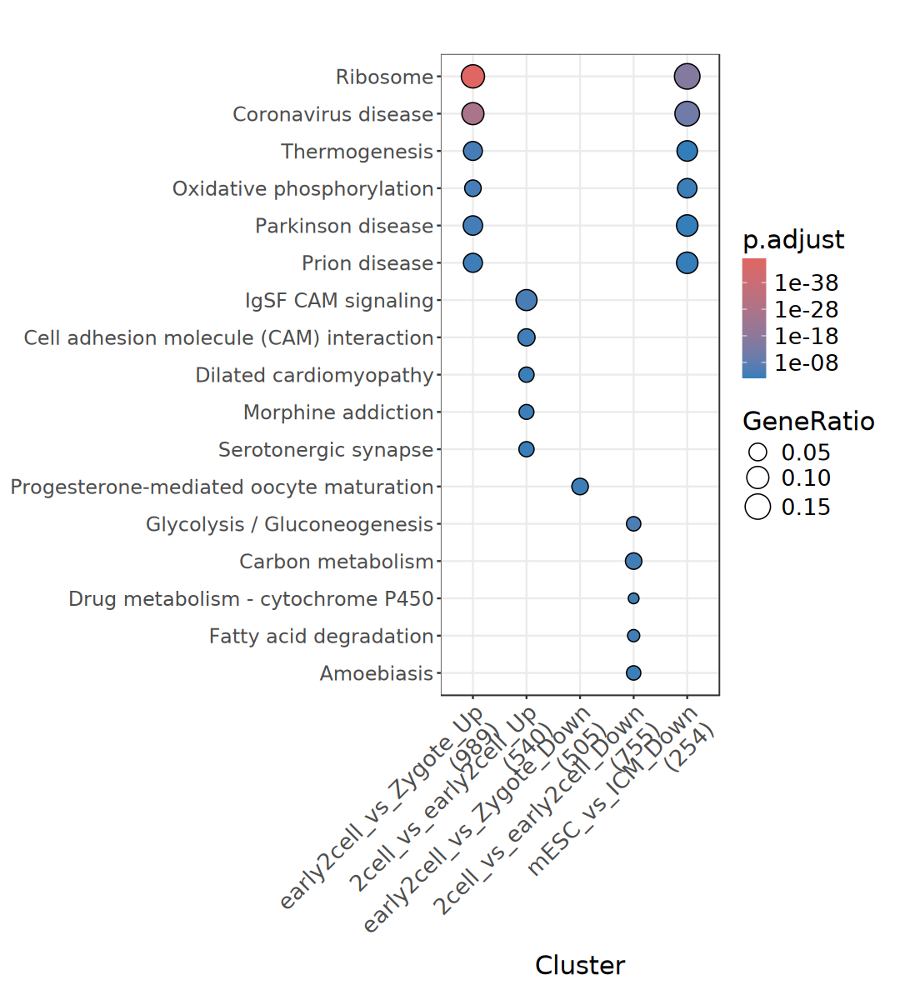

In [164]:
options(repr.plot.width = 9, repr.plot.height = 10)

dotplot(ekegg_compare, showCategory = 5, label_format = 40) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

### Part 2

In [165]:
gene_map <- bitr(
    rowData(dds)$symbol, OrgDb = org.Mm.eg.db, fromType = "SYMBOL", 
    toType = c("ENTREZID"), drop = FALSE)

'select()' returned 1:1 mapping between keys and columns

Warning message in bitr(rowData(dds)$symbol, OrgDb = org.Mm.eg.db, fromType = "SYMBOL", :
"10.29% of input gene IDs are fail to map..."


In [166]:
membership_df <- cl_mfuzz$membership |> 
    as.data.frame() |> 
    rownames_to_column(var = "gene_id") |> 
    pivot_longer(cols = -gene_id, names_to = "cluster", values_to = "membership")

In [167]:
cluster_df <- cl_mfuzz$cluster |> 
    data.frame(cluster = _) |>
    mutate(cluster = as.character(cluster)) |>
    rownames_to_column(var = "gene_id") |>
    left_join(membership_df, by = c("gene_id", "cluster")) |>
    filter(membership > 0.6) |>
    left_join(
        rowData(dds) |> as.data.frame() |> 
        dplyr::select(symbol, type) |>
        rownames_to_column("gene_id"), 
        by = "gene_id") |>
    left_join(gene_map, by = c("symbol" = "SYMBOL"))

table(cluster_df$cluster)
head(cluster_df)


   1    2    3    4    5    6    7    8    9 
 562  466 1589  823 1250  517  799  674 1115 

,gene_id,cluster,membership,symbol,type,ENTREZID
,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>
1,ENSMUSG00000033845.13,7,0.9850320,Mrpl15,protein_coding,27395
2,ENSMUSG00000025903.14,8,0.7670500,Lypla1,protein_coding,18777
3,ENSMUSG00000062588.4,2,0.7812655,Gm6104,processed_pseudogene,619829
4,ENSMUSG00000033793.12,6,0.6768132,Atp6v1h,protein_coding,108664
5,ENSMUSG00000104046.1,2,0.9559326,Gm37567,TEC,NA
6,ENSMUSG00000025907.14,4,0.6219032,Rb1cc1,protein_coding,12421


In [168]:
# membership_df <- cl_tcseq@membership |> 
#     as.data.frame() |> 
#     rownames_to_column(var = "gene_id") |> 
#     pivot_longer(cols = -gene_id, names_to = "cluster", values_to = "membership")

# cluster_df <- cl_tcseq@cluster |> 
#     data.frame(cluster = _) |>
#     mutate(cluster = as.character(cluster)) |>
#     rownames_to_column(var = "gene_id") |>
#     left_join(membership_df, by = c("gene_id", "cluster")) |>
#     filter(membership > 0.6) |>
#     left_join(
#         rowData(dds) |> as.data.frame() |> 
#         dplyr::select(symbol, type) |>
#         rownames_to_column("gene_id"), 
#         by = "gene_id") |>
#     left_join(gene_map, by = c("gene_id" = "ENSEMBL"))

# table(cluster_df$cluster)

In [169]:
gene_list <- split(cluster_df$symbol, cluster_df$cluster)

In [170]:
ego_cluster_compare <- compareCluster(
    geneCluster = gene_list, fun = enrichGO,
    universe = rowData(dds)$symbol, 
    OrgDb = org.Mm.eg.db, ont = "ALL", 
    keyType = 'SYMBOL', pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500, readable = TRUE)

In [171]:
ego_cluster_compare |> dplyr::select(-geneID) |> head()

,Cluster,ONTOLOGY,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,1,BP,GO:0000280,nuclear division,38/491,422/13982,0.09004739,2.564242,6.224694,1.004006e-07,0.0002329781,0.0002225753,38
2,1,BP,GO:0048285,organelle fission,41/491,479/13982,0.08559499,2.437452,6.107084,1.248209e-07,0.0002329781,0.0002225753,41
3,1,BP,GO:0140014,mitotic nuclear division,27/491,255/13982,0.10588235,3.015167,6.195568,3.236785e-07,0.0004027640,0.0003847799,27
4,1,BP,GO:0000819,sister chromatid segregation,24/491,221/13982,0.10859729,3.092479,5.981637,9.297126e-07,0.0008676543,0.0008289122,24
5,1,BP,GO:0000070,mitotic sister chromatid segregation,20/491,183/13982,0.10928962,3.112194,5.486854,6.813039e-06,0.0050866151,0.0048594899,20
6,1,BP,GO:0007059,chromosome segregation,33/491,416/13982,0.07932692,2.258959,4.973021,1.110937e-05,0.0059819214,0.0057148194,33


In [172]:
gene_list <- split(cluster_df$ENTREZID, cluster_df$cluster)

In [ ]:
ekegg_cluster_compare <- compareCluster(
    geneCluster = gene_list, fun = enrichKEGG, 
    universe = unique(gene_map$ENTREZID), 
    organism = "mmu", pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500)

In [174]:
ekegg_cluster_compare |> dplyr::select(-geneID) |> head()

,Cluster,category,subcategory,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,early2cell_vs_Zygote_Up,Genetic Information Processing,Translation,mmu03010,Ribosome,115/989,188/6193,0.6117021,3.830406,17.179720,1.797261e-46,6.164606e-44,5.864747e-44,115
2,early2cell_vs_Zygote_Up,Human Diseases,Infectious disease: viral,mmu05171,Coronavirus disease,98/989,203/6193,0.4827586,3.022977,12.775282,5.218071e-28,8.948992e-26,8.513695e-26,98
3,early2cell_vs_Zygote_Up,Genetic Information Processing,Translation,mmu03008,Ribosome biogenesis in eukaryotes,26/989,74/6193,0.3513514,2.200120,4.527364,3.982418e-05,4.553232e-03,4.331753e-03,26
4,early2cell_vs_Zygote_Up,Organismal Systems,Environmental adaptation,mmu04714,Thermogenesis,52/989,196/6193,0.2653061,1.661315,4.101234,8.569157e-05,7.348052e-03,6.990628e-03,52
5,early2cell_vs_Zygote_Up,Human Diseases,Neurodegenerative disease,mmu05012,Parkinson disease,59/989,234/6193,0.2521368,1.578850,3.934889,1.387938e-04,9.521254e-03,9.058121e-03,59
6,2cell_vs_early2cell_Up,Environmental Information Processing,Signaling molecules and interaction,mmu04517,IgSF CAM signaling,44/540,237/6193,0.1856540,2.129176,5.478119,8.369356e-07,2.611239e-04,2.035075e-04,44


### Clustered Heatmap

In [175]:
norm_mat <- log2(tpm + 1)

#### 1). Heatmap-ggplot2

In [176]:
plot_df <- norm_mat |> t() |> scale() |> t() |> 
    as.data.frame() |> 
    rownames_to_column("gene_id") |>
    pivot_longer(cols = -gene_id, names_to = "sample", values_to = "expression") |>
    right_join(cluster_df, by = "gene_id") |>
    mutate(
        sample = factor(sample, levels = colnames(dds)), 
        cluster = as.factor(cluster)) |>
    arrange(cluster, membership, sample, expression)

head(plot_df)

gene_id,sample,expression,cluster,membership,symbol,type,ENTREZID
<chr>,<fct>,<dbl>,<fct>,<dbl>,<chr>,<chr>,<chr>
ENSMUSG00000048827.12,MIIoocyte_rep1,0.01217233,1,0.6001836,Pkd1l3,protein_coding,244646
ENSMUSG00000048827.12,MIIoocyte_rep2,0.03961037,1,0.6001836,Pkd1l3,protein_coding,244646
ENSMUSG00000048827.12,Zygote_rep1,0.56086712,1,0.6001836,Pkd1l3,protein_coding,244646
ENSMUSG00000048827.12,Zygote_rep2,0.96519073,1,0.6001836,Pkd1l3,protein_coding,244646
ENSMUSG00000048827.12,early2cell_rep1,0.64315245,1,0.6001836,Pkd1l3,protein_coding,244646
ENSMUSG00000048827.12,early2cell_rep2,-0.06981633,1,0.6001836,Pkd1l3,protein_coding,244646


In [177]:
line_plot <- ggplot(plot_df, aes(x = sample, y = expression)) +
    geom_path(
        aes(group = gene_id, color = membership),
        linewidth = 0.5, alpha = 0.5) +
    scale_color_distiller(
        palette = "RdYlBu", limits = c(0.6, 1), 
        breaks = seq(0.6, 1, 0.2)) +
    scale_y_continuous(breaks = c(-2, 0, 2)) + 
    facet_wrap(
        ~ cluster, ncol = 1, strip.position = "left",
        labeller = "label_both") + 
    coord_cartesian(clip = "off") + 
    theme_classic() +
    theme(
        panel.border = element_rect(color = "grey", fill = NA, linewidth = 1),
        strip.text = element_text(size = 16),
        strip.background = element_rect(fill = brewer.pal(6, "Set3"), colour = NA),
        legend.title = element_text(size = 18, vjust = 1),
        legend.text = element_text(size = 16),
        legend.position = "top", 
        axis.title = element_blank(),
        axis.text.x = element_blank(),
        axis.text.y = element_text(size = 16),
        axis.ticks.x = element_blank())

In [178]:
heatmap_plot <- ggplot(plot_df, aes(x = sample, y = gene_id)) +
    geom_tile(aes(fill = expression)) +
    scale_fill_distiller(palette = "RdYlBu", breaks = c(-2, 0, 2)) +
    facet_wrap(~ cluster, ncol = 1, scales = "free_y") + 
    theme_void() +
    theme(
        panel.border = element_rect(color = "grey", fill = NA, linewidth = 1),
        strip.text = element_blank(),
        legend.title = element_text(size = 18, vjust = 1),
        legend.text = element_text(size = 16),
        legend.position = "top", 
        axis.title = element_blank(),
        axis.text.x = element_blank(),
        axis.text.y = element_blank(),
        axis.ticks.y = element_blank())

In [179]:
strip_plot <- colData(dds) |> as.data.frame() |> 
    rownames_to_column("sample") |>
    mutate(sample = factor(sample, levels = colnames(dds))) |>
    ggplot(aes(x = sample, y = 1)) +
        geom_tile(aes(color = Stage, fill = Stage), width = 1, height = 1) +
        scale_x_discrete(expand = c(0, 0)) +
        scale_color_brewer(palette = "Set3") +
        scale_fill_brewer(palette = "Set3") +
        theme_void() +
        theme(
            legend.title = element_text(size = 18, vjust = 1),
            legend.text = element_text(size = 16))

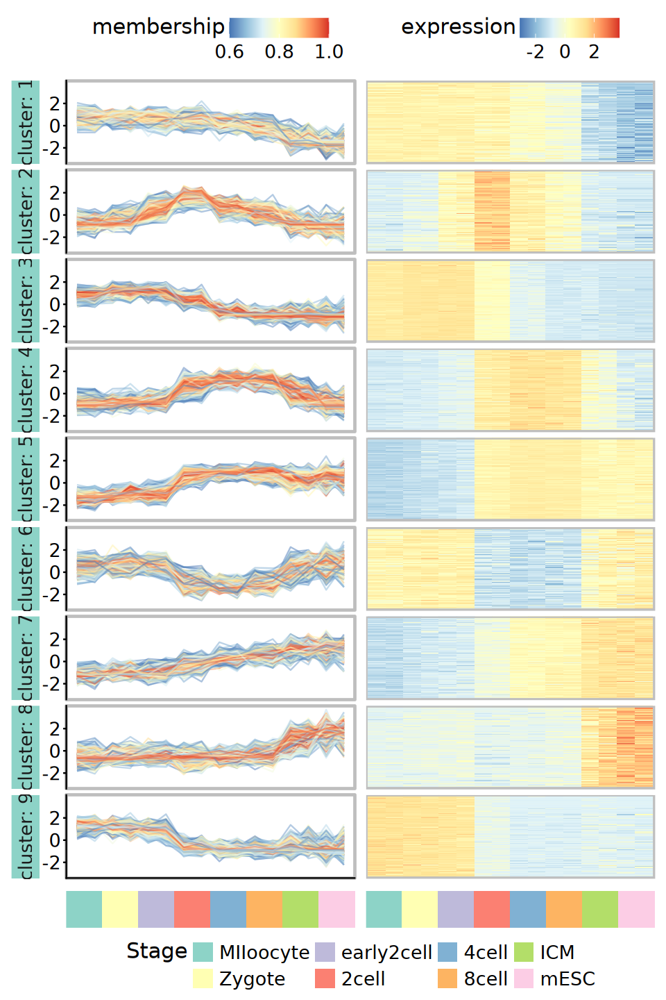

In [180]:
options(repr.plot.width = 8, repr.plot.height = 12)

(line_plot + heatmap_plot) / 
    (strip_plot + strip_plot + plot_layout(guides = "collect") & 
    theme(legend.position = "bottom")) + 
    plot_layout(heights = c(1, 0.05)) & 
    theme(strip.placement = "outside", plot.margin = margin(5, 5, 5, 5))

In [181]:
go_annotations <- ego_cluster_compare |> as.data.frame() |> 
    dplyr::select(Cluster, ONTOLOGY, ID, Description, p.adjust, Count) |>
    mutate(
        ONTOLOGY = factor(ONTOLOGY, levels = c("BP", "MF", "CC")),
        GO_term = paste0(Description, " (", ONTOLOGY, ")")) |>
    group_by(Cluster) |> 
    arrange(ONTOLOGY, p.adjust, .by_group = TRUE) |>
    slice_head(n = 5) |>
    summarise(GO_term = paste(GO_term, collapse = "\n")) |>
    left_join(
        plot_df |> group_by(cluster) |> 
            summarise(y_pos = mean(as.numeric(factor(gene_id)))), 
        by = c("Cluster" = "cluster"))
    
head(go_annotations)

Cluster,GO_term,y_pos
<fct>,<chr>,<dbl>
1,nuclear division (BP) organelle fission (BP) mitotic nuclear division (BP) sister chromatid segregation (BP) mitotic sister chromatid segregation (BP),281.5
2,oxidoreduction-driven active transmembrane transporter activity (MF) triplet codon-amino acid adaptor activity (MF) electron transfer activity (MF) NADH dehydrogenase (ubiquinone) activity (MF) active monoatomic ion transmembrane transporter activity (MF),233.5
3,synaptic membrane (CC),795.0
4,autophagosome organization (BP) autophagosome assembly (BP) phospholipid metabolic process (BP) nucleophagy (BP),412.0
5,ribonucleoprotein complex biogenesis (BP) ribosome biogenesis (BP) rRNA processing (BP) rRNA metabolic process (BP) ribosomal small subunit biogenesis (BP),625.5
6,"tricarboxylic acid cycle (BP) purine-containing compound metabolic process (BP) oxidoreductase activity, acting on the aldehyde or oxo group of donors, NAD or NADP as acceptor (MF) oxidoreductase activity, acting on the aldehyde or oxo group of donors (MF)",259.0


In [182]:
annotation_plot <- ggplot(go_annotations, aes(x = 0, y = y_pos)) +
    geom_text(
        aes(color = GO_term, label = GO_term), 
        hjust = 0, size = 4, show.legend = FALSE) +
    facet_wrap(~ Cluster, ncol = 1, scales = "free_y") +
    scale_color_brewer(palette = "Dark2") + 
    xlim(c(0, 1)) +
    theme_test() + 
    theme(
        strip.text = element_blank(),
        axis.title = element_blank(),
        axis.text = element_blank(),
        axis.ticks = element_blank())

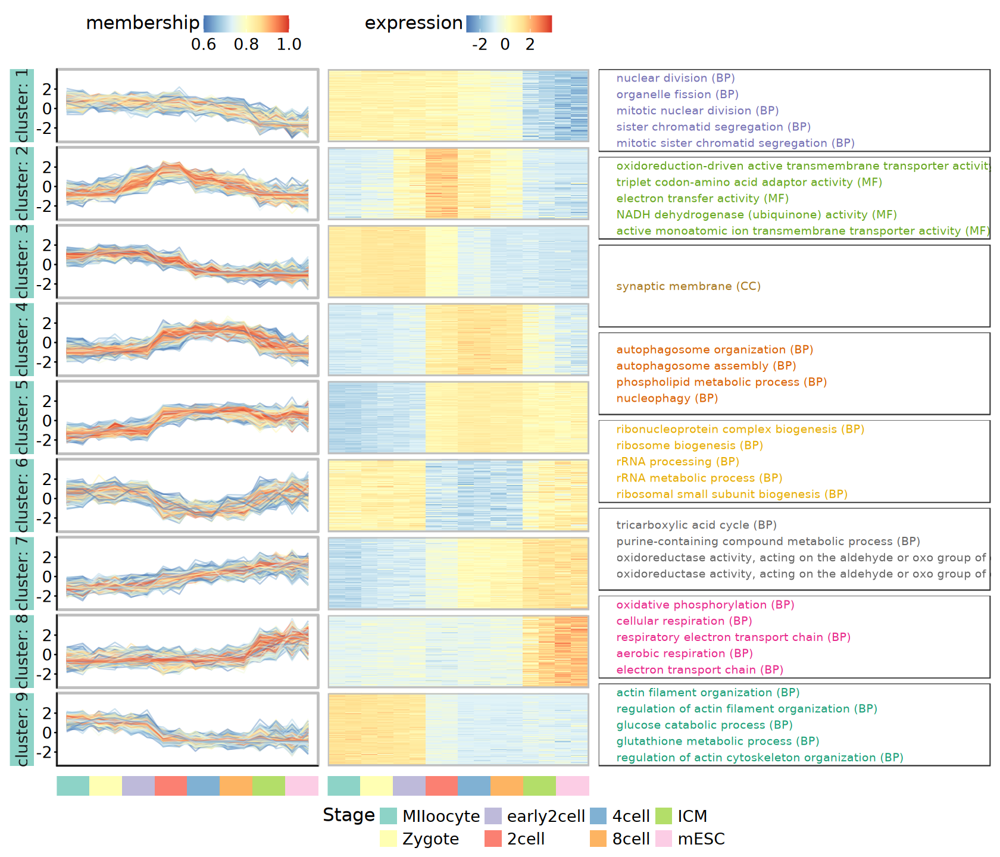

In [183]:
options(repr.plot.width = 14, repr.plot.height = 12)
top_row <- line_plot + heatmap_plot + annotation_plot +
    plot_layout(widths = c(2, 2, 3))
bottom_row <- strip_plot + strip_plot + plot_spacer() +
    plot_layout(widths = c(2, 2, 3), guides = "collect") & 
    theme(legend.position = "bottom")

top_row / bottom_row + 
    plot_layout(heights = c(1, 0.03)) &
    theme(
        plot.margin = margin(5, 5, 5, 5),
        strip.placement = "outside")

#### 2). ComplexHeatmap

In [184]:
cluster_df <- cluster_df |>
    mutate(cluster = factor(paste0("cluster", cluster)))

In [185]:
ac <- colData(dds) |> 
    as.data.frame() |>
    dplyr::select(Stage, Replicate)

group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Stage)),
    levels(dds$Stage))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Replicate)),
    levels(dds$Replicate))

top_anno <- HeatmapAnnotation(
    df = ac, col = list(
        Stage = group_colors, 
        Replicate = replicate_colors))

In [186]:
ar <- cluster_df |> 
    dplyr::select(gene_id, Cluster = cluster) |>
    column_to_rownames("gene_id") |>
    arrange(Cluster)

cluster_colors <- setNames(
    scales::brewer_pal(palette = "Set3")(nlevels(ar$Cluster)),
    levels(ar$Cluster))

left_anno <- rowAnnotation(
    df = ar, col = list(Cluster = cluster_colors),
    show_legend = FALSE)

In [187]:
heatmap_dat <- norm_mat[rownames(ar), ]

heatmap_col <- circlize::colorRamp2(
    breaks = c(-2, 0, 2), 
    colors = brewer.pal(n = 11, name = "RdYlBu")[c(3,6,9)] |> rev())

In [188]:
gene_labels <- cluster_df |>
    filter(type == "protein_coding") |>
    group_by(cluster) |>
    slice_max(order_by = membership, n = 5, with_ties = FALSE) |>
    ungroup()

mark_rows <- which(rownames(heatmap_dat) %in% gene_labels$gene_id)
mark_labels <- gene_labels$symbol[
    match(rownames(heatmap_dat)[mark_rows], 
    gene_labels$gene_id)]

right_anno <- rowAnnotation(
    foo = anno_mark(
        at = mark_rows,
        labels = mark_labels,
        labels_gp = gpar(fontsize = 12)),
    width = unit(2.5, "cm"))

In [189]:
lg_heatmap <- Legend(
    title = "Expression (z-score)", col_fun = heatmap_col)

lg_group <- Legend(
    title = "Stage", labels = levels(dds$Stage))

lg_replicate <- Legend(
    title = "Replicate", labels = levels(dds$Replicate))

lg_cluster <- Legend(
    labels = levels(ar$Cluster), title = "Cluster", 
    legend_gp = gpar(fill = cluster_colors))

combined_leg <- list(lg_heatmap, lg_group, lg_replicate) |>
    packLegend(direction = "vertical")

In [190]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(
        name = "Expression", col = heatmap_col, 
        row_split = factor(ar$Cluster),
        cluster_row_slices = FALSE, cluster_columns = FALSE,
        top_annotation = top_anno,
        left_annotation = left_anno, 
        right_annotation = right_anno,
        show_row_names = FALSE, show_column_names = FALSE, 
        use_raster = TRUE)

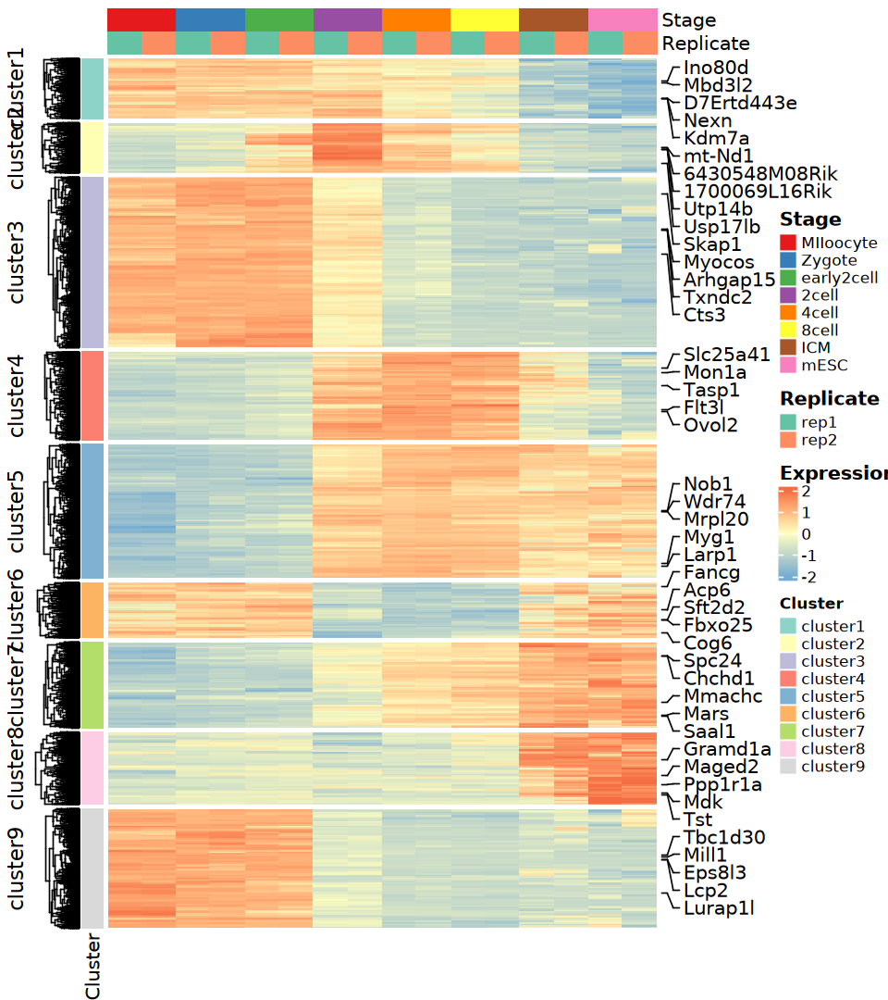

In [191]:
options(repr.plot.width = 8, repr.plot.height = 9)
draw(
    ht + combined_leg, merge_legend = TRUE,
    annotation_legend_list = list(lg_cluster), 
    legend_title_gp = gpar(fontsize = 12, fontface = "bold"),
    legend_labels_gp = gpar(fontsize = 10), 
    padding = unit(c(2, 2, 2, 2), "mm"))

In [192]:
go_annotations <- ego_cluster_compare |> as.data.frame() |> 
    dplyr::select(Cluster, ONTOLOGY, ID, Description, p.adjust, Count) |>
    mutate(
        ONTOLOGY = factor(ONTOLOGY, levels = c("BP", "MF", "CC")),
        GO_term = paste0(Description, " (", ONTOLOGY, ")")) |>
    group_by(Cluster) |> 
    arrange(ONTOLOGY, p.adjust, .by_group = TRUE) |>
    slice_head(n = 5) |>
    summarise(GO_term = paste(GO_term, collapse = "\n")) |>
    mutate(Cluster = factor(paste0("cluster", Cluster)))

head(go_annotations)

Cluster,GO_term
<fct>,<chr>
cluster1,nuclear division (BP) organelle fission (BP) mitotic nuclear division (BP) sister chromatid segregation (BP) mitotic sister chromatid segregation (BP)
cluster2,oxidoreduction-driven active transmembrane transporter activity (MF) triplet codon-amino acid adaptor activity (MF) electron transfer activity (MF) NADH dehydrogenase (ubiquinone) activity (MF) active monoatomic ion transmembrane transporter activity (MF)
cluster3,synaptic membrane (CC)
cluster4,autophagosome organization (BP) autophagosome assembly (BP) phospholipid metabolic process (BP) nucleophagy (BP)
cluster5,ribonucleoprotein complex biogenesis (BP) ribosome biogenesis (BP) rRNA processing (BP) rRNA metabolic process (BP) ribosomal small subunit biogenesis (BP)
cluster6,"tricarboxylic acid cycle (BP) purine-containing compound metabolic process (BP) oxidoreductase activity, acting on the aldehyde or oxo group of donors, NAD or NADP as acceptor (MF) oxidoreductase activity, acting on the aldehyde or oxo group of donors (MF)"


In [193]:
go_term_data_list <- split(go_annotations$GO_term, go_annotations$Cluster)

In [194]:
right_annotation <- rowAnnotation(
    textbox = anno_textbox(
        ar$Cluster, go_term_data_list,
        background_gp = gpar(fill = "#ffffff"),
        gp = gpar(fontsize = 12), max_width = unit(10, "cm"), 
        add_new_line = TRUE, round_corners = TRUE), 
    width = unit(12, "cm"))
# word_wrap = TRUE, 

In [195]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(
        name = "Expression", col = heatmap_col, 
        row_split = factor(ar$Cluster),
        top_annotation = top_anno,
        left_annotation = left_anno, 
        right_annotation = right_anno,
        cluster_row_slices = FALSE, cluster_columns = FALSE,
        show_row_names = FALSE, show_column_names = FALSE, 
        width = unit(8, "cm"), use_raster = TRUE) +
    Heatmap(
        ar$Cluster, name = "Cluster", 
        col = cluster_colors,
        show_column_names = FALSE,
        right_annotation = right_annotation,
        width = unit(0.3, "cm"))

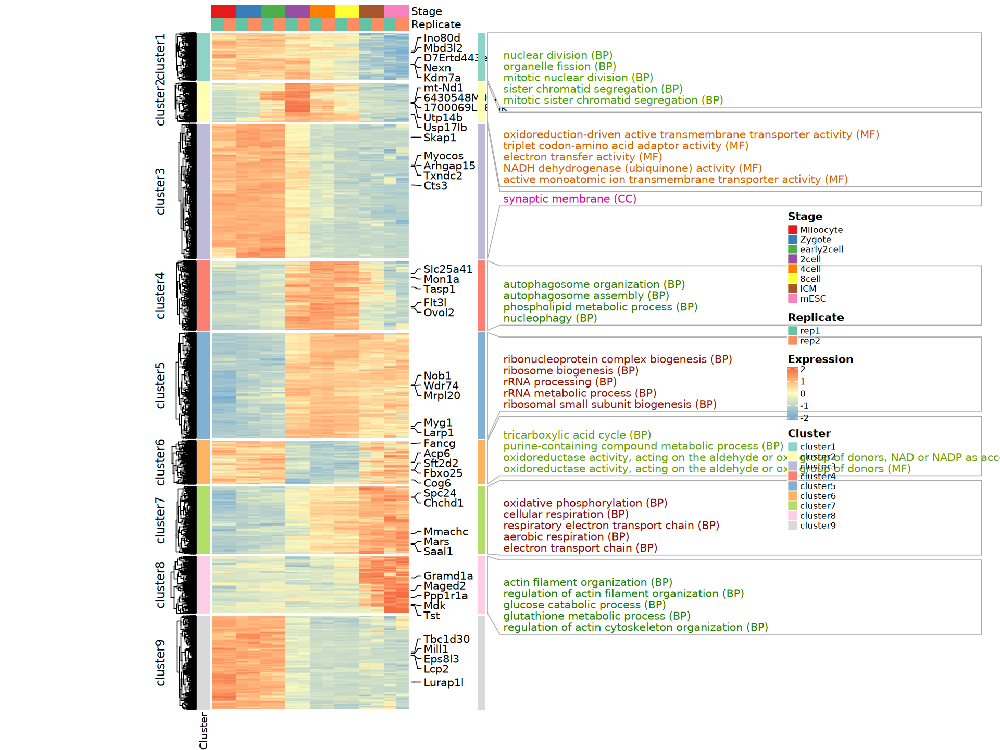

In [196]:
options(repr.plot.width = 16, repr.plot.height = 12)
draw(
    ht + combined_leg, merge_legend = TRUE,
    # annotation_legend_list = list(lg_cluster), 
    legend_title_gp = gpar(fontsize = 12, fontface = "bold"),
    legend_labels_gp = gpar(fontsize = 10), 
    padding = unit(c(2, 2, 2, 2), "mm"))

In [197]:
s_heatmap_dat <- heatmap_dat |> t() |> scale() |> t()

In [198]:
panel_fun_boxplot <- function(s_heatmap_dat, group_colors = NULL) {
    function(index, nm) {
        tmp <- s_heatmap_dat[index, , drop = FALSE]
        pos <- seq(0, 1, length.out = ncol(tmp))
        rng <- range(tmp, na.rm = TRUE)
        norm <- (tmp - rng[1]) / (rng[2] - rng[1])
        fills <- if (is.null(group_colors)) "grey70" else group_colors |>
            rep(each = 3)
        bw <- min(0.1, 0.9 / max(1, ncol(tmp)))

        grid::pushViewport(grid::viewport(xscale = c(-0.1, 1.1), yscale = c(0, 1.2)))
        grid::grid.rect()                         
        for (i in seq_len(ncol(norm))) {
            grid.boxplot(
                norm[, i], pos = pos[i],
                direction = "vertical",
                box_width = bw, outline = FALSE,
                gp = grid::gpar(col = "grey50", fill = fills[i]))
        }
        grid::grid.lines(
            x = pos, y = apply(norm, 2, median, na.rm = TRUE),
            gp = grid::gpar(col = "red", lwd = 0.5))
        grid::grid.text(
            paste0("Genes: ", nrow(tmp)), 0.5, 0.9, 
            gp = grid::gpar(fontsize = 6))
        grid::popViewport()
    }
}

In [199]:
panel_fun <- panel_fun_boxplot(s_heatmap_dat, group_colors)
left_anno2 <- rowAnnotation(
    boxplot = anno_link(
        align_to = factor(ar$Cluster), which = "row",
        panel_fun = panel_fun, side = "left",
        size = grid::unit(3, "cm"),
        width = grid::unit(6, "cm"),
        gap = grid::unit(0.25, "cm"),
        link_gp = grid::gpar(fill = "grey90", col = NA)))

In [200]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(
        name = "Expression", col = heatmap_col, 
        row_split = factor(ar$Cluster),
        top_annotation = top_anno,
        left_annotation = left_anno2, 
        right_annotation = right_anno,
        cluster_row_slices = FALSE, cluster_columns = FALSE,
        show_row_names = FALSE, show_column_names = FALSE, 
        show_row_dend = FALSE,
        width = unit(8, "cm"), use_raster = TRUE) +
    Heatmap(
        ar$Cluster, name = "Cluster", 
        col = cluster_colors,
        show_column_names = FALSE,
        right_annotation = right_annotation,
        width = unit(0.3, "cm"))

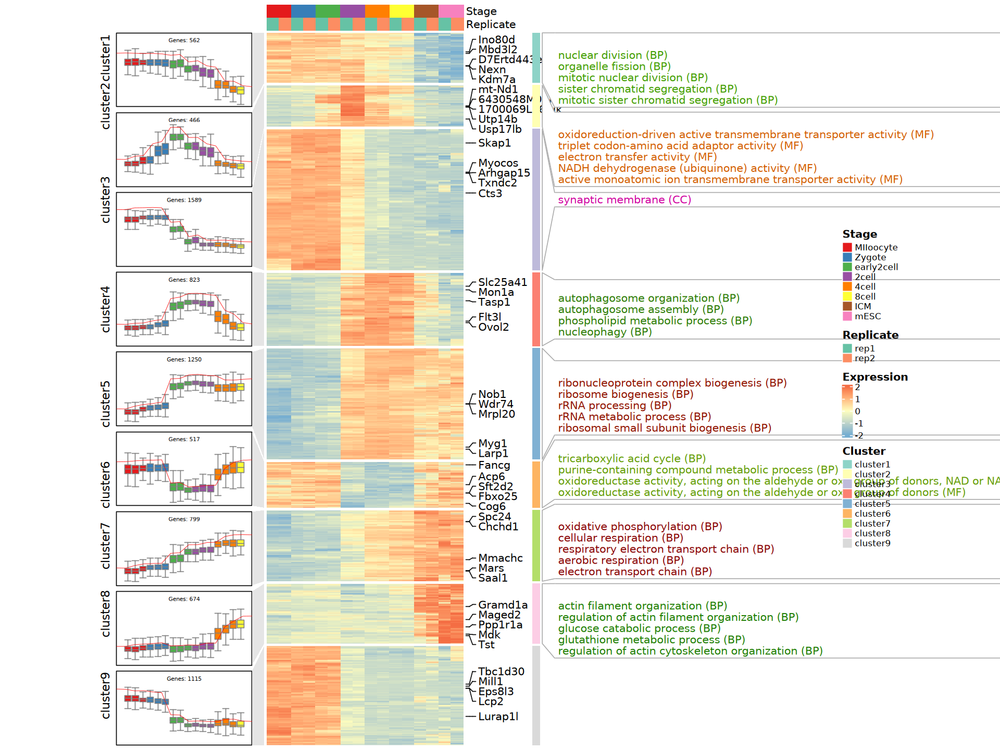

In [201]:
options(repr.plot.width = 16, repr.plot.height = 12)
draw(
    ht + combined_leg, merge_legend = TRUE,
    # annotation_legend_list = list(lg_cluster), 
    legend_title_gp = gpar(fontsize = 12, fontface = "bold"),
    legend_labels_gp = gpar(fontsize = 10), 
    padding = unit(c(2, 2, 2, 2), "mm"))

In [202]:
panel_fun_pathplot <- function(
    s_heatmap_dat, cluster_df, palette = c("blue","white","red")) {
    
    function(index, nm) {
        tmp <- s_heatmap_dat[index, , drop = FALSE]
        # pos <- scales::rescale(1:ncol(tmp), to = c(0, 1))
        pos <- seq(0, 1, length.out = ncol(tmp))
        rng <- range(tmp, na.rm = TRUE)
        norm <- (tmp - rng[1]) / (rng[2] - rng[1])
        
        mem <- cluster_df$membership[match(rownames(tmp), cluster_df$gene_id)]
        mem_idx <- round(mem * 100)
        line_colors <- grDevices::colorRampPalette(palette)(100)
        line_cols <- line_colors[mem_idx]

        pushViewport(grid::viewport(xscale = c(-0.1, 1.1), yscale = c(0, 1.2)))
        grid.rect()
        for (i in seq_len(nrow(norm))) {
            grid.lines(
                x = pos, y = norm[i, ], 
                gp = gpar(col = line_cols[i], lwd = 0.5))
        }
        grid.text(paste0("Genes: ", nrow(tmp)), 0.5, 0.9, gp = grid::gpar(fontsize = 6))
        popViewport()
    }
}

In [203]:
palette = c(
    "#5E4FA2", "#3288BD", "#66C2A5", "#ABDDA4", 
    "#E6F598", "#FFFFBF", "#FEE08B", "#FDAE61", 
    "#F46D43", "#D53E4F", "#9E0142")

In [204]:
panel_fun <- panel_fun_pathplot(s_heatmap_dat, cluster_df, palette)
left_anno3 <- rowAnnotation(
    boxplot = anno_link(
        align_to = factor(ar$Cluster), which = "row",
        panel_fun = panel_fun, side = "left",
        size = grid::unit(3, "cm"),
        width = grid::unit(6, "cm"),
        gap = grid::unit(0.25, "cm"),
        link_gp = grid::gpar(fill = "grey90", col = NA)))

In [205]:
line_colors <- circlize::colorRamp2(
    breaks = seq(0, 1, length.out = length(palette)), 
    colors = palette)

lg_line <- Legend(
    title = "Membership", col_fun = line_colors, 
    at = c(0, 0.5, 1), labels = c("0", "0.5", "1"))

In [206]:
combined_leg <- list(lg_heatmap, lg_group, lg_replicate, lg_line) |>
    packLegend(direction = "vertical")

In [207]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(
        name = "Expression", col = heatmap_col, 
        row_split = factor(ar$Cluster),
        top_annotation = top_anno,
        left_annotation = left_anno3, 
        right_annotation = right_anno,
        cluster_row_slices = FALSE, cluster_columns = FALSE,
        show_row_names = FALSE, show_column_names = FALSE, 
        show_row_dend = FALSE,
        width = unit(8, "cm"), use_raster = TRUE) +
    Heatmap(
        ar$Cluster, name = "Cluster", 
        col = cluster_colors,
        show_column_names = FALSE,
        right_annotation = right_annotation,
        width = unit(0.3, "cm"))

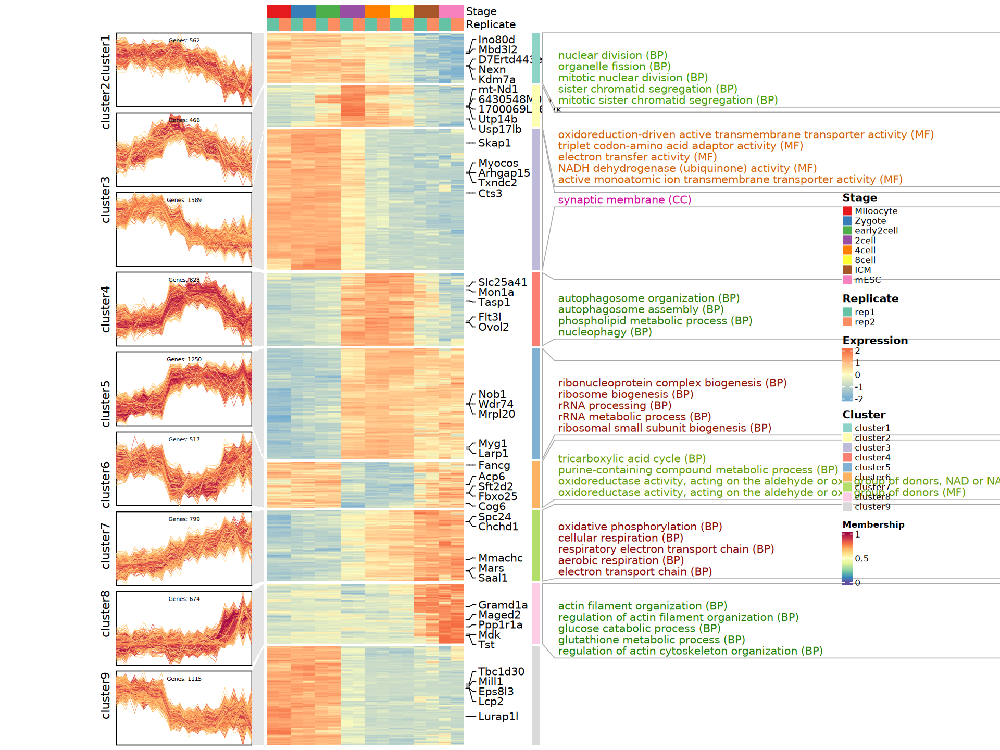

In [208]:
options(repr.plot.width = 16, repr.plot.height = 12)
draw(
    ht + combined_leg, merge_legend = TRUE,
    annotation_legend_list = list(lg_line),
    legend_title_gp = gpar(fontsize = 12, fontface = "bold"),
    legend_labels_gp = gpar(fontsize = 10), 
    padding = unit(c(2, 2, 2, 2), "mm"))

#### 3). [ClusterGVis](https://github.com/junjunlab/ClusterGVis)

> - To enhance clustering and visualization of time-series gene expression data from RNA-Seq experiments.

In [209]:
suppressPackageStartupMessages(library(ClusterGVis))

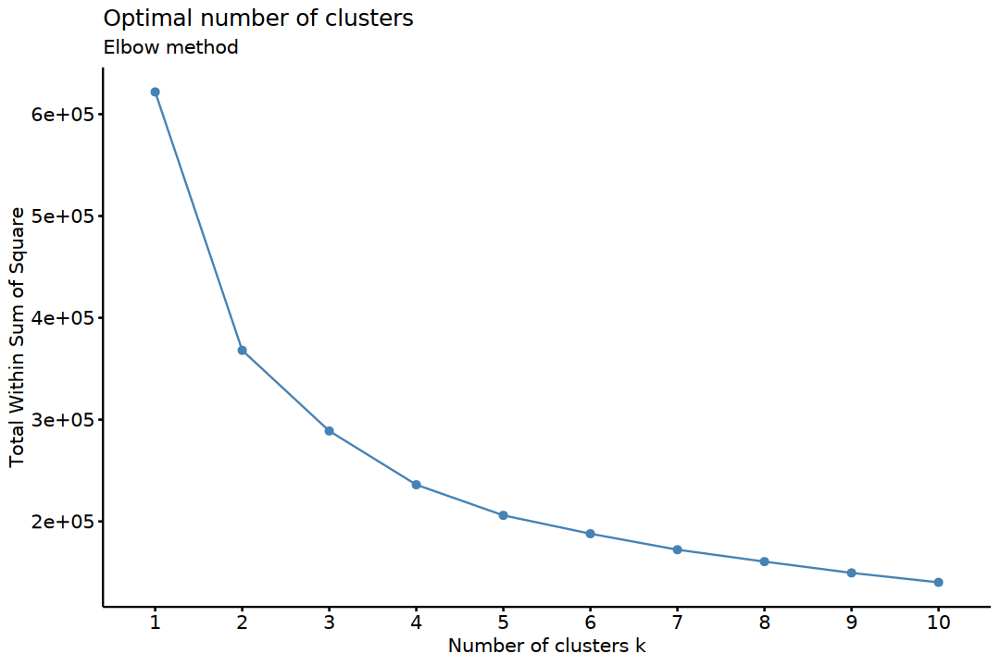

In [210]:
options(repr.plot.width = 9, repr.plot.height = 6)
getClusters(norm_mean_mat)
# ~ 2 min

In [211]:
cl <- clusterData(norm_mean_mat, cluster.method = "mfuzz", cluster.num = 9)

[1] "0 genes excluded.\n"


Warning message:
"Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the ClusterGVis package.
  Please report the issue at <https://github.com/junjunlab/ClusterGVis/issues>."


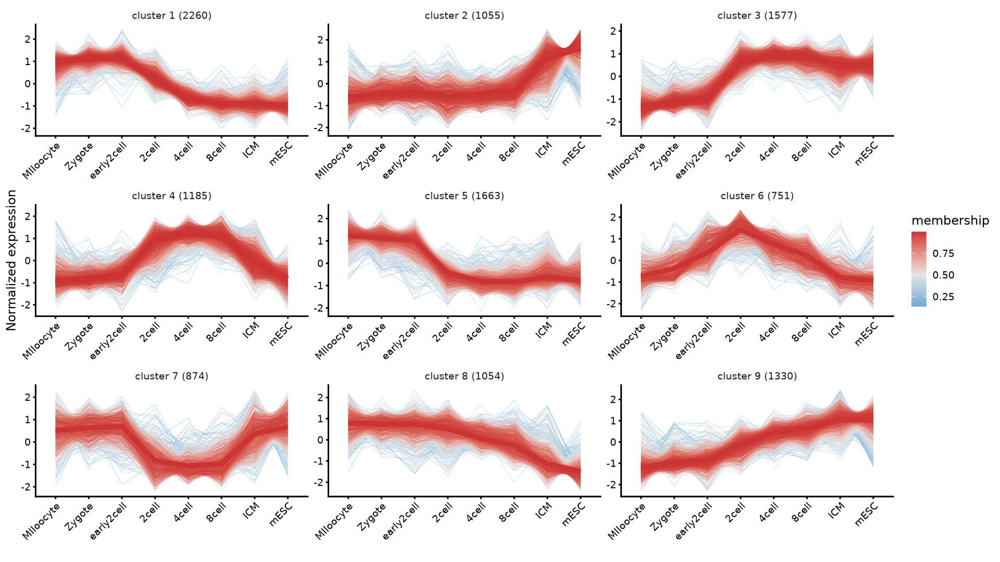

In [212]:
options(repr.plot.width = 16, repr.plot.height = 9)
visCluster(object = cl, plot.type = "line", ncol = 3)

In [213]:
markGenes = rownames(norm_mean_mat)[
    sample(1:nrow(norm_mean_mat), 30, replace = F)]

In [214]:
go_annotations <- ego_cluster_compare |> as.data.frame() |> 
    dplyr::select(Cluster, ONTOLOGY, ID, Description, p.adjust, Count) |>
    mutate(
        ONTOLOGY = factor(ONTOLOGY, levels = c("BP", "MF", "CC")), 
        GO_term = paste0(Description, " (", ONTOLOGY, ")")) |>
    group_by(Cluster) |> 
    arrange(ONTOLOGY, p.adjust, .by_group = TRUE) |>
    slice_head(n = 5) |>
    ungroup() |>
    mutate(Cluster = factor(paste0("C", Cluster))) |>
    dplyr::select(id = Cluster, term = GO_term)

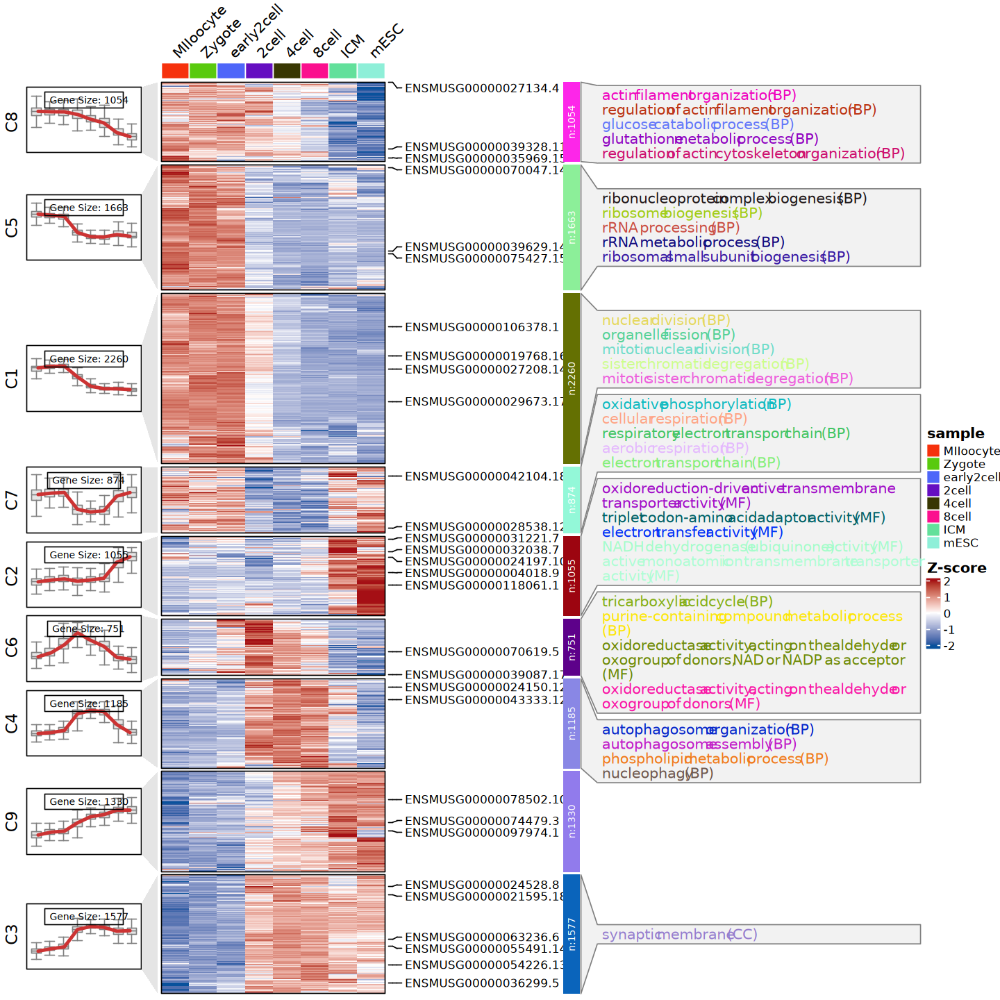

In [215]:
options(repr.plot.width = 12, repr.plot.height = 12)
visCluster(
    object = cl, 
    # HeatmapAnnotation = top_anno,
    plot.type = "both", line.side = "left", add.box = TRUE,
    markGenes = markGenes, genes.gp = c('italic', 10, "black"),
    annoTerm.data = go_annotations, 
    column_names_rot = 45, show_row_dend = FALSE)

In [216]:
go_annotations <- ego_cluster_compare |> as.data.frame() |> 
    mutate(ONTOLOGY = factor(ONTOLOGY, levels = c("BP", "MF", "CC"))) |>
    group_by(Cluster) |> 
    arrange(ONTOLOGY, qvalue, .by_group = TRUE) |>
    slice_head(n = 5) |>
    ungroup() |>
    dplyr::select(group = Cluster, Description, qvalue, ratio = Count) |>
    mutate(group = factor(paste0("C", group)))

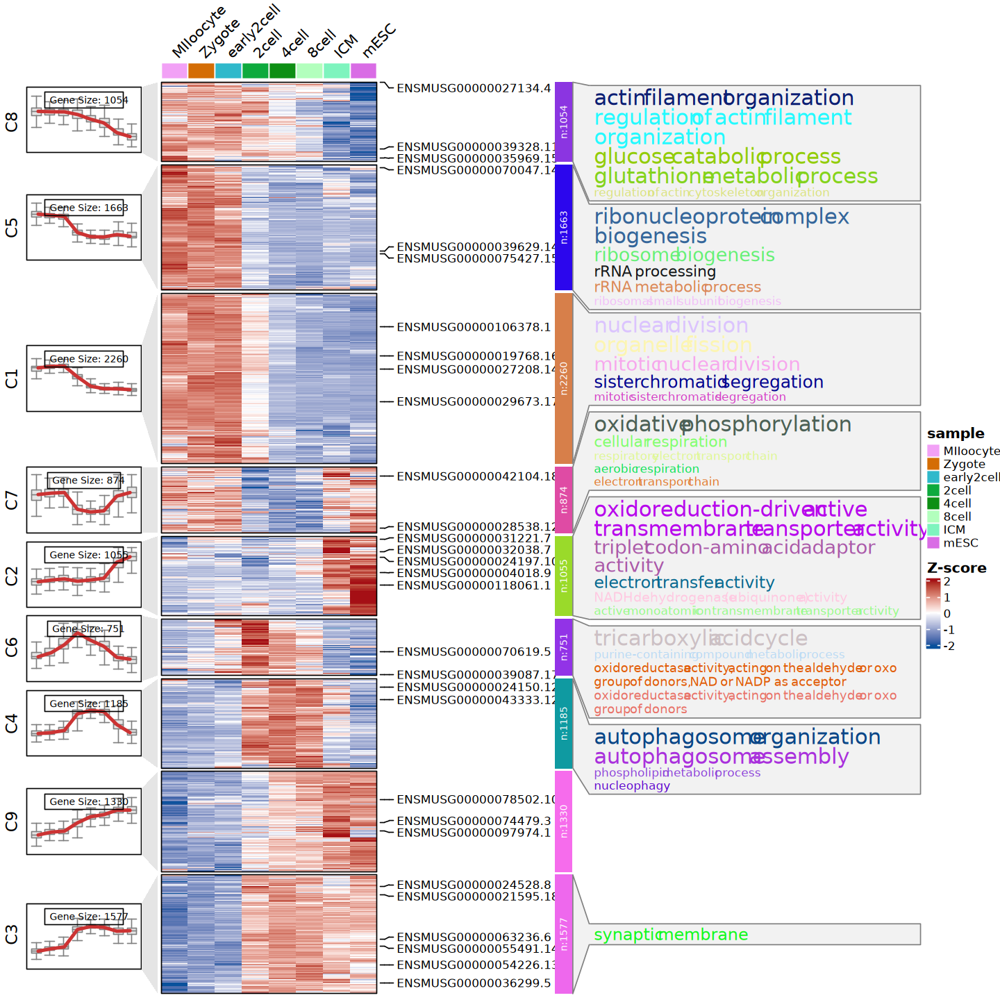

In [217]:
options(repr.plot.width = 12, repr.plot.height = 12)
visCluster(
    object = cl, 
    # HeatmapAnnotation = top_anno,
    plot.type = "both", line.side = "left", add.box = TRUE,
    markGenes = markGenes, genes.gp = c('italic', 10, "black"),
    annoTerm.data = go_annotations, go.size = "pval",
    # go.col = rep(ggsci::pal_d3()(6), each = 5), 
    column_names_rot = 45, show_row_dend = FALSE)

# Reference

> 1. Law CW, Alhamdoosh M, Su S, Dong X, Tian L, Smyth GK, Ritchie ME (2018). “RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR.” F1000Research, 5, 1408. https://f1000research.com/articles/5-1408/v3. [RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR](https://www.bioconductor.org/packages/release/workflows/html/RNAseq123.html)
> 2. Law CW, Zeglinski K, Dong X, Alhamdoosh M, Smyth GK, Ritchie ME (2020). “A guide to creating design matrices for gene expression experiments.” F1000Research, 9, 1444. https://f1000research.com/articles/9-1444. [A guide to creating design matrices for gene expression experiments](https://www.bioconductor.org/packages/release/workflows/vignettes/RNAseq123/inst/doc/designmatrices.html)
> 2. Love MI, Anders S, Kim V, Huber W (2016). “RNA-Seq workflow: gene-level exploratory analysis and differential expression.” F1000Research. doi:10.12688/f1000research.7035.2. [RNA-seq workflow: gene-level exploratory analysis and differential expression](https://www.bioconductor.org/packages/release/workflows/html/rnaseqGene.html)
> 3. Chen Y, Lun ATL, Smyth GK (2016). “From reads to genes to pathways: differential expression analysis of RNA-Seq experiments using Rsubread and the edgeR quasi-likelihood pipeline.” F1000Research, 5, 1438. http://f1000research.com/articles/5-1438. [Gene-level RNA-seq differential expression and pathway analysis using Rsubread and the edgeR quasi-likelihood pipeline](https://www.bioconductor.org/packages/release/workflows/html/RnaSeqGeneEdgeRQL.html)